# ICU Mortality Prediction on MIMIC-IV: Data Preparation & Exploratory Data Analysis

**Project:** *Calibration, Missing Data, Validation Design and Subgroup Reporting in Machine-Learning Models for ICU Mortality Prediction on MIMIC Data*
**Team:** Mudassar, Touseef, Ifraz

This notebook is the **data component** of the project (the optional empirical case study, protocol §6). It builds the fixed
analysis cohort described in the protocol and prepares it for modelling:

| Protocol requirement | Where in this notebook |
|---|---|
| Adult, **first ICU stay**, ICU stay **≥ 24 h** | §3 Cohort construction |
| Features from the **first 24 h** of the ICU stay | §4 Feature extraction |
| Transparent **missing-data** handling (imputation + indicator) | §5, §8 |
| **Patient-grouped split**, **train-only** preprocessing (no leakage) | §8 |
| Subgroups: age band, sex, admission type, race, insurance | §7 EDA |
| `anchor_year_group` as the only time-aware field | §7 EDA |

### Notebook outline
1. Environment setup
2. Dataset loading and description
3. Cohort construction
4. Feature extraction (first 24 h of ICU stay)
5. Data cleaning: duplicates, missing values, outliers
6. Feature engineering
7. Exploratory Data Analysis (EDA)
8. Preprocessing & transformations (train-only fit)
9. Feature selection
10. Key observations and insights
11. Save outputs

> **Data use note:** MIMIC-IV is credentialed data (PhysioNet DUA). Keep the data folder private, do not share
> row-level outputs, and **clear cell outputs** before pushing this notebook to a public repository.

## 1. Environment setup

The notebook detects where it is running and configures itself:

| | **Kaggle (GPU notebook)** | **Local PC** |
|---|---|---|
| Data source | your private Kaggle dataset, attached under *Input* (`/kaggle/input/...`) | `E:\\patients data.zip` |
| Folder layout | any: files are found recursively (flat, or `hosp/` + `icu/`), `.csv.gz` or `.csv` | extracted once into `E:\\patients data\\data\\` |
| Outputs | `/kaggle/working/` (processed files + figures) | `E:\\patients data\\` |
| XGBoost | `device="cuda"` on the Kaggle GPU (T4 / P100) | GPU if an NVIDIA card is present, else CPU |

**Kaggle settings (right-hand panel → Session options):** Accelerator = **GPU T4 x2** or **GPU P100**;
Internet can stay **off** (all libraries are pre-installed); attach the dataset with **+ Add Input → Your Datasets**.

Note: only the XGBoost steps (§9) use the GPU. Reading `chartevents` is CPU/disk-bound on every machine.


In [1]:
# --- Install any missing libraries into the current kernel (Kaggle already has all of them) ---
import importlib.util, subprocess, sys

REQUIRED = {"pandas": "pandas", "numpy": "numpy", "matplotlib": "matplotlib", "seaborn": "seaborn",
            "sklearn": "scikit-learn", "scipy": "scipy", "xgboost": "xgboost", "pyarrow": "pyarrow"}
missing = [pip_name for mod, pip_name in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", missing, "(needs Internet ON in Kaggle session options)")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All required libraries are already installed.")


All required libraries are already installed.


In [2]:
import os, json, time, gc, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import xgboost as xgb
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("pandas", pd.__version__, "| numpy", np.__version__, "| xgboost", xgb.__version__)

pandas 3.1.1 | numpy 2.5.4 | xgboost 3.4.1


In [3]:
# --- Data paths: Kaggle (GPU notebook) or local PC, detected automatically ---
import zipfile

IN_KAGGLE = Path("/kaggle/input").exists()
NEEDED_FILES = ["patients", "admissions", "icustays", "d_items", "chartevents",
                "outputevents", "inputevents", "procedureevents"]

def extract_from_zip(zip_path, names, dest):
    # Stream the requested members out of a zip (any folder depth) into dest
    with zipfile.ZipFile(zip_path) as z:
        members = {Path(m).name: m for m in z.namelist()}
        for f in names:
            key = f"{f}.csv.gz" if f"{f}.csv.gz" in members else f"{f}.csv"
            if key not in members:
                continue
            print(f"Extracting {key} from {zip_path.name} ...")
            with z.open(members[key]) as src, open(dest / key, "wb") as dst:
                while chunk := src.read(16 * 1024 * 1024):
                    dst.write(chunk)

def find_files(root):
    # Map each needed table to its file anywhere under root (prefers .csv.gz over .csv)
    found = {}
    for p in sorted(root.rglob("*.csv*")):
        for f in NEEDED_FILES:
            if p.name in (f"{f}.csv.gz", f"{f}.csv") and (f not in found or p.name.endswith(".gz")):
                found[f] = p
    return found

if IN_KAGGLE:
    INPUT_ROOT = Path("/kaggle/input")               # read-only: attached datasets
    PROJECT_DIR = Path("/kaggle/working")            # writable (~20 GB), kept with the notebook version
    DATA_DIR = PROJECT_DIR / "data"                  # only used if a zip has to be extracted
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    FILES = find_files(INPUT_ROOT)
    still_missing = [f for f in NEEDED_FILES if f not in FILES]
    if still_missing:                                # dataset uploaded as a zip that Kaggle did not unpack
        for zp in sorted(INPUT_ROOT.rglob("*.zip")):
            extract_from_zip(zp, still_missing, DATA_DIR)
        FILES.update(find_files(DATA_DIR))
else:
    ZIP_PATH = Path(r"E:\patients data.zip")        # local dataset archive
    PROJECT_DIR = Path(r"E:\patients data")          # project folder
    DATA_DIR = PROJECT_DIR / "data"
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    todo = [f for f in NEEDED_FILES if f not in find_files(DATA_DIR)]
    if todo:
        assert ZIP_PATH.exists(), f"Dataset zip not found: {ZIP_PATH}"
        extract_from_zip(ZIP_PATH, todo, DATA_DIR)
    FILES = find_files(DATA_DIR)

missing_files = [f for f in NEEDED_FILES if f not in FILES]
assert not missing_files, (f"Not found: {missing_files}. On Kaggle, attach your dataset via '+ Add Input' "
                           f"and check that it contains these MIMIC-IV tables (hosp/ and icu/ modules).")

def raw(name):
    # Path of a raw MIMIC-IV table, wherever it lives (Kaggle input or local folder)
    return FILES[name]

PROC_DIR = PROJECT_DIR / "processed" if IN_KAGGLE else DATA_DIR / "processed"     # cached + processed outputs
FIG_DIR = PROJECT_DIR / "figures" if IN_KAGGLE else PROJECT_DIR / "1_eda" / "figures"
PROC_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Running on :", "Kaggle" if IN_KAGGLE else "local PC")
for f in NEEDED_FILES:
    print(f"  {f:<16} {raw(f)}")
print("Outputs to :", PROC_DIR, "|", FIG_DIR)


Running on : local PC
  patients         E:\patients data\data\patients.csv.gz
  admissions       E:\patients data\data\admissions.csv.gz
  icustays         E:\patients data\data\icustays.csv.gz
  d_items          E:\patients data\data\d_items.csv.gz
  chartevents      E:\patients data\data\chartevents.csv.gz
  outputevents     E:\patients data\data\outputevents.csv.gz
  inputevents      E:\patients data\data\inputevents.csv.gz
  procedureevents  E:\patients data\data\procedureevents.csv.gz
Outputs to : E:\patients data\data\processed | E:\patients data\1_eda\figures


In [4]:
# --- GPU detection (NVIDIA GPU used by XGBoost if present, otherwise CPU) ---
def detect_gpu():
    try:
        r = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                           capture_output=True, text=True, timeout=20)
        return r.stdout.strip() if r.returncode == 0 and r.stdout.strip() else None
    except Exception:
        return None

GPU_NAME = detect_gpu()
XGB_DEVICE = "cuda" if GPU_NAME else "cpu"
print("GPU:", GPU_NAME or "not available -> using CPU")
print("XGBoost device:", XGB_DEVICE)
if IN_KAGGLE and not GPU_NAME:
    print("Tip: Kaggle -> Session options -> Accelerator -> GPU T4 x2 (or P100), then restart the session.")


GPU: not available -> using CPU
XGBoost device: cpu


In [5]:
# --- Plot style: one consistent palette for the whole notebook ---
# Outcome colours: blue = survived, orange = died (colour-blind-safe pair)
C_SURV, C_DIED = "#2a78d6", "#eb6834"
OUTCOME_PALETTE = {0: C_SURV, 1: C_DIED}
OUTCOME_LABELS = {0: "Survived", 1: "Died in hospital"}
C_MAIN = "#2a78d6"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
})

def savefig(name):
    # Save the current figure to 1_eda/figures/<name>.png
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

def wilson_ci(k, n, z=1.96):
    # 95% Wilson confidence interval for a proportion k/n
    if n == 0:
        return np.nan, np.nan
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

## 2. Dataset loading and description

**Source:** MIMIC-IV (Medical Information Mart for Intensive Care, v3.x), PhysioNet — Johnson et al., *Scientific Data*
(2023). De-identified EHR data from ICU admissions at Beth Israel Deaconess Medical Center, Boston.
Access requires PhysioNet credentialing: <https://physionet.org/content/mimiciv/>.

| File | Module | Content | Used for |
|---|---|---|---|
| `patients.csv.gz` | hosp | one row per patient: sex, anchor age/year, date of death | demographics |
| `admissions.csv.gz` | hosp | one row per hospital admission: type, insurance, race, **`hospital_expire_flag`** | outcome + demographics |
| `icustays.csv.gz` | icu | one row per ICU stay: care unit, in/out time, length of stay | cohort |
| `chartevents.csv.gz` | icu | all charted observations (vitals, labs charted in the ICU, GCS…) — **~430 M rows** | physiology features |
| `outputevents.csv.gz` | icu | fluid outputs (urine) | urine output |
| `inputevents.csv.gz` | icu | infusions / medications | vasopressor use |
| `procedureevents.csv.gz` | icu | procedures (ventilation, lines…) | ventilation flags |
| `d_items.csv.gz`, `d_labitems.csv.gz` | dictionaries | item id → label | lookups |

Note: `labevents` (hosp module) is **not** in our data folder, so laboratory values are taken from the lab items that
are also charted in `chartevents` (e.g. *Creatinine (serum)*, *Lactic Acid*, *WBC*).

In [6]:
# File inventory
inventory = pd.DataFrame({"table": list(FILES),
                          "file": [str(p) for p in FILES.values()],
                          "size_MB": [round(p.stat().st_size / 1e6, 1) for p in FILES.values()]})
inventory


,table,file,size_MB
0,admissions,E:\patients data\data\admissions.csv.gz,19.9
1,chartevents,E:\patients data\data\chartevents.csv.gz,3502.4
2,d_items,E:\patients data\data\d_items.csv.gz,0.1
3,icustays,E:\patients data\data\icustays.csv.gz,3.3
4,inputevents,E:\patients data\data\inputevents.csv.gz,401.1
5,outputevents,E:\patients data\data\outputevents.csv.gz,49.3
6,patients,E:\patients data\data\patients.csv.gz,2.8
7,procedureevents,E:\patients data\data\procedureevents.csv.gz,24.1


In [7]:
# Load the small/medium tables fully into memory
t0 = time.time()
patients = pd.read_csv(raw("patients"), parse_dates=["dod"])
admissions = pd.read_csv(raw("admissions"),
                         parse_dates=["admittime", "dischtime", "deathtime", "edregtime", "edouttime"])
icustays = pd.read_csv(raw("icustays"), parse_dates=["intime", "outtime"])
d_items = pd.read_csv(raw("d_items"))
print(f"Loaded in {time.time() - t0:.1f}s")

def describe_table(df, name):
    # Compact structural summary of a table: rows, columns, memory, missing cells
    return pd.Series({
        "rows": f"{len(df):,}", "columns": df.shape[1],
        "memory_MB": round(df.memory_usage(deep=True).sum() / 1e6, 1),
        "missing_cells_%": round(100 * df.isna().mean().mean(), 2),
    }, name=name)

pd.concat([describe_table(patients, "patients"), describe_table(admissions, "admissions"),
           describe_table(icustays, "icustays"), describe_table(d_items, "d_items")], axis=1).T

Loaded in 1.4s


,rows,columns,memory_MB,missing_cells_%
patients,"364,627",6,21.9,14.92
admissions,"546,028",16,110.9,11.92
icustays,"94,458",8,12.5,0.0
d_items,"4,095",9,0.6,30.18


In [8]:
# Column-level description: type, % missing, number of unique values
def column_profile(df):
    return pd.DataFrame({"dtype": df.dtypes.astype(str),
                         "missing_%": (100 * df.isna().mean()).round(2),
                         "n_unique": df.nunique()})

for name, df in [("patients", patients), ("admissions", admissions), ("icustays", icustays)]:
    print(f"\n=== {name} ===")
    display(column_profile(df))


=== patients ===


,dtype,missing_%,n_unique
subject_id,int64,0.0,364627
gender,str,0.0,2
anchor_age,int64,0.0,73
anchor_year,int64,0.0,99
anchor_year_group,str,0.0,5
dod,datetime64[us],89.5,22424



=== admissions ===


,dtype,missing_%,n_unique
subject_id,int64,0.00,223452
hadm_id,int64,0.00,546028
admittime,datetime64[us],0.00,534919
dischtime,datetime64[us],0.00,528871
deathtime,datetime64[us],97.84,11788
admission_type,str,0.00,9
admit_provider_id,str,0.00,2045
admission_location,str,0.00,11
discharge_location,str,27.44,13
insurance,str,1.71,5



=== icustays ===


,dtype,missing_%,n_unique
subject_id,int64,0.00,65366
hadm_id,int64,0.00,85242
stay_id,int64,0.00,94458
first_careunit,str,0.00,17
last_careunit,str,0.00,17
intime,datetime64[us],0.00,94449
outtime,datetime64[us],0.01,94442
los,float64,0.01,84932


In [9]:
icustays.head()

[Output removed before publishing: it showed individual patient rows from MIMIC-IV, which the PhysioNet data-use agreement does not allow to be shared. Re-run this cell locally with credentialed access to see it.]


In [10]:
# Numeric summary statistics
display(patients[["anchor_age", "anchor_year"]].describe().T)
display(icustays[["los"]].describe().T)
print("Hospital mortality (all admissions):", round(100 * admissions["hospital_expire_flag"].mean(), 2), "%")

,count,mean,std,min,25%,50%,75%,max
anchor_age,364627.0,48.875097,20.943316,18.0,29.0,48.0,65.0,91.0
anchor_year,364627.0,2150.835404,23.395666,2110.0,2131.0,2151.0,2171.0,2208.0


,count,mean,std,min,25%,50%,75%,max
los,94444.0,3.630025,5.402474,0.00125,1.096212,1.965648,3.862575,226.403079


Hospital mortality (all admissions): 2.16 %


In [11]:
# Peek at the structure of the big table without loading it (first 5 rows only)
pd.read_csv(raw("chartevents"), nrows=5)

[Output removed before publishing: it showed individual patient rows from MIMIC-IV, which the PhysioNet data-use agreement does not allow to be shared. Re-run this cell locally with credentialed access to see it.]


## 3. Cohort construction

Inclusion rules (protocol §6), applied in order so that a **cohort flow** can be reported:

1. All ICU stays in MIMIC-IV.
2. Keep only the **first ICU stay per patient** → one row per patient, so there is no patient-level leakage between
   train and test later on.
3. **Adults** (age ≥ 18 at ICU admission). MIMIC-IV shifts dates per patient; age at admission =
   `anchor_age + (year(intime) − anchor_year)`.
4. ICU length of stay **≥ 24 h**, so a full 24-hour observation window exists.
5. Outcome available.

**Outcome:** `hospital_expire_flag` = 1 if the patient died during the same hospital admission (in-hospital mortality).

In [12]:
# Check key uniqueness before merging (duplicates in key columns would silently multiply rows)
print("Duplicate subject_id in patients :", patients["subject_id"].duplicated().sum())
print("Duplicate hadm_id in admissions  :", admissions["hadm_id"].duplicated().sum())
print("Duplicate stay_id in icustays    :", icustays["stay_id"].duplicated().sum())
print("Fully duplicated rows (pat/adm/icu):",
      patients.duplicated().sum(), admissions.duplicated().sum(), icustays.duplicated().sum())

Duplicate subject_id in patients : 0
Duplicate hadm_id in admissions  : 0
Duplicate stay_id in icustays    : 0


Fully duplicated rows (pat/adm/icu): 0 0 0


In [13]:
adm_cols = ["subject_id", "hadm_id", "admittime", "dischtime", "deathtime", "admission_type",
            "admission_location", "insurance", "language", "marital_status", "race", "hospital_expire_flag"]
pat_cols = ["subject_id", "gender", "anchor_age", "anchor_year", "anchor_year_group", "dod"]

stays = (icustays
         .merge(admissions[adm_cols], on=["subject_id", "hadm_id"], how="left")
         .merge(patients[pat_cols], on="subject_id", how="left"))
stays["age"] = stays["anchor_age"] + (stays["intime"].dt.year - stays["anchor_year"])

flow = [("All ICU stays", len(stays), stays["subject_id"].nunique())]

# Step 2: first ICU stay per patient
stays = stays.sort_values(["subject_id", "intime"])
stays["icu_stay_seq"] = stays.groupby("subject_id").cumcount() + 1
stays["n_icu_stays_patient"] = stays.groupby("subject_id")["stay_id"].transform("count")
cohort = stays[stays["icu_stay_seq"] == 1].copy()
flow.append(("First ICU stay per patient", len(cohort), cohort["subject_id"].nunique()))

# Step 3: adults
cohort = cohort[cohort["age"] >= 18]
flow.append(("Age >= 18", len(cohort), cohort["subject_id"].nunique()))

# Step 4: ICU stay >= 24 h (los is in days)
cohort = cohort[cohort["los"] >= 1]
flow.append(("ICU stay >= 24 h", len(cohort), cohort["subject_id"].nunique()))

# Step 5: outcome available
cohort = cohort[cohort["hospital_expire_flag"].notna()].copy()
cohort["mortality"] = cohort["hospital_expire_flag"].astype(int)
flow.append(("Outcome available", len(cohort), cohort["subject_id"].nunique()))

flow_df = pd.DataFrame(flow, columns=["step", "stays", "patients"])
flow_df["excluded"] = (-flow_df["stays"].diff()).fillna(0).astype(int)
flow_df

,step,stays,patients,excluded
0,All ICU stays,94458,65366,0
1,First ICU stay per patient,65366,65366,29092
2,Age >= 18,65366,65366,0
3,ICU stay >= 24 h,51838,51838,13528
4,Outcome available,51838,51838,0


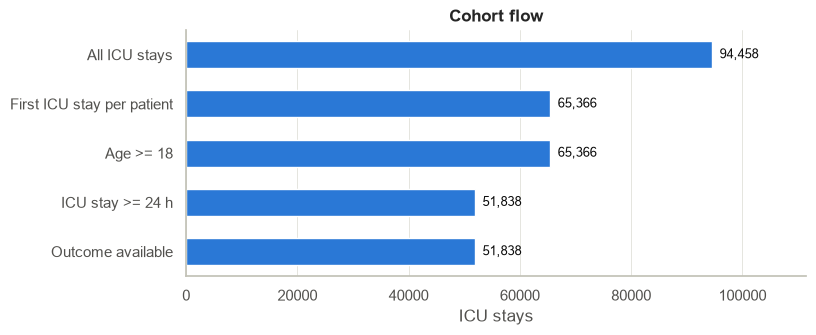

Final cohort: 51,838 stays | deaths: 5,522 | in-hospital mortality: 10.65%


In [14]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(flow_df["step"][::-1], flow_df["stays"][::-1], color=C_MAIN, height=0.55)
for y, v in enumerate(flow_df["stays"][::-1]):
    ax.text(v, y, f"  {v:,}", va="center", fontsize=9, color="#0b0b0b")
ax.set_xlabel("ICU stays")
ax.set_title("Cohort flow")
ax.set_xlim(0, flow_df["stays"].max() * 1.18)
ax.grid(axis="y", visible=False)
savefig("01_cohort_flow"); plt.show()

print(f"Final cohort: {len(cohort):,} stays | deaths: {cohort['mortality'].sum():,} "
      f"| in-hospital mortality: {100 * cohort['mortality'].mean():.2f}%")

## 4. Feature extraction — first 24 h of the ICU stay

All features are computed from measurements taken in the window **[ICU intime, intime + 24 h)**. Anything recorded
after that window would not be available to a model at prediction time (*time leakage*), so it is never used.

### 4.1 Item definitions
Item IDs were checked against `d_items`. Arterial and non-invasive blood pressure are merged into one variable;
Fahrenheit temperatures are converted to Celsius.

In [15]:
CHART_ITEMS = {
    # vital signs
    220045: "heart_rate",
    220179: "sbp", 220050: "sbp",          # non-invasive / arterial systolic BP
    220180: "dbp", 220051: "dbp",          # diastolic BP
    220181: "mbp", 220052: "mbp",          # mean BP
    220210: "resp_rate",
    220277: "spo2",
    223762: "temperature", 223761: "temperature",   # Celsius / Fahrenheit (converted below)
    # Glasgow Coma Scale components
    220739: "gcs_eye", 223900: "gcs_verbal", 223901: "gcs_motor",
    # anthropometrics
    226512: "weight", 226730: "height",
    # labs charted in the ICU
    220545: "hematocrit", 220228: "hemoglobin", 227457: "platelets", 220546: "wbc",
    225624: "bun", 220615: "creatinine", 220645: "sodium", 227442: "potassium",
    220602: "chloride", 227443: "bicarbonate", 220621: "glucose", 225625: "calcium",
    225668: "lactate", 223830: "ph", 220224: "pao2", 220235: "paco2", 223835: "fio2",
    225690: "bilirubin", 227466: "ptt", 227467: "inr", 220587: "ast",
}
URINE_ITEMS = [226559, 226560, 226561, 226584, 226563, 226564, 226565, 226567, 226557, 226558]
VASOPRESSOR_ITEMS = {221906: "norepinephrine", 221289: "epinephrine", 221662: "dopamine",
                     222315: "vasopressin", 221749: "phenylephrine", 221653: "dobutamine"}
VENT_ITEMS = {225792: "invasive_vent", 225794: "noninvasive_vent"}

# Show the dictionary labels for transparency
d_items.set_index("itemid").loc[list(CHART_ITEMS), ["label", "category", "unitname"]].assign(
    variable=pd.Series(CHART_ITEMS))

,label,category,unitname,variable
itemid,,,,
220045,Heart Rate,Routine Vital Signs,bpm,heart_rate
220179,Non Invasive Blood Pressure systolic,Routine Vital Signs,mmHg,sbp
220050,Arterial Blood Pressure systolic,Routine Vital Signs,mmHg,sbp
220180,Non Invasive Blood Pressure diastolic,Routine Vital Signs,mmHg,dbp
220051,Arterial Blood Pressure diastolic,Routine Vital Signs,mmHg,dbp
220181,Non Invasive Blood Pressure mean,Routine Vital Signs,mmHg,mbp
220052,Arterial Blood Pressure mean,Routine Vital Signs,mmHg,mbp
220210,Respiratory Rate,Respiratory,insp/min,resp_rate
220277,O2 saturation pulseoxymetry,Respiratory,%,spo2


### 4.2 Chart events (chunked read)

`chartevents.csv.gz` is ~3.5 GB compressed (~430 million rows) and does not fit in memory. It is streamed in chunks;
each chunk is filtered to **(a)** our item IDs and **(b)** our cohort stays, and only then are timestamps parsed and the
24-hour window applied. The result is cached to `data/processed/`, so the slow step (≈15–30 min) runs **only once**.

In [16]:
window = cohort[["stay_id", "intime"]].copy()
window["window_end"] = window["intime"] + pd.Timedelta(hours=24)
COHORT_STAYS = np.array(sorted(window["stay_id"].unique()), dtype="float64")

def in_first_24h(df, time_col):
    # Attach each stay's window and keep rows with intime <= time < intime + 24h
    df = df.merge(window, on="stay_id", how="inner")
    keep = (df[time_col] >= df["intime"]) & (df[time_col] < df["window_end"])
    return df.loc[keep].drop(columns=["intime", "window_end"])

def extract_chartevents(cache_path, chunksize=3_000_000):
    if cache_path.exists():
        print("Loading cached chart events:", cache_path.name)
        return pd.read_parquet(cache_path)
    item_ids = np.array(list(CHART_ITEMS), dtype="int64")
    reader = pd.read_csv(raw("chartevents"),
                         usecols=["stay_id", "charttime", "itemid", "valuenum"],
                         dtype={"stay_id": "float64", "itemid": "int64", "valuenum": "float64", "charttime": "str"},
                         chunksize=chunksize)
    parts, n_rows, t0 = [], 0, time.time()
    for i, chunk in enumerate(reader, 1):
        n_rows += len(chunk)
        chunk = chunk[chunk["itemid"].isin(item_ids) & chunk["stay_id"].isin(COHORT_STAYS)]
        if len(chunk):
            chunk = chunk.assign(stay_id=chunk["stay_id"].astype("int64"),
                                 charttime=pd.to_datetime(chunk["charttime"]))
            parts.append(in_first_24h(chunk, "charttime"))
        if i % 10 == 0:
            print(f"  chunk {i:>3}: {n_rows / 1e6:,.0f}M rows scanned, {time.time() - t0:,.0f}s elapsed")
    out = pd.concat(parts, ignore_index=True)
    print(f"Scanned {n_rows:,} rows in {time.time() - t0:,.0f}s -> kept {len(out):,} rows")
    out.to_parquet(cache_path, index=False)
    return out

chart = extract_chartevents(PROC_DIR / "chartevents_first24h.parquet")
chart["variable"] = chart["itemid"].map(CHART_ITEMS)
print(f"{len(chart):,} measurements | {chart['stay_id'].nunique():,} stays with any chart data")
chart.head()

Loading cached chart events: chartevents_first24h.parquet


12,508,198 measurements | 51,835 stays with any chart data


[Output removed before publishing: it showed individual patient rows from MIMIC-IV, which the PhysioNet data-use agreement does not allow to be shared. Re-run this cell locally with credentialed access to see it.]


### 4.3 Urine output, vasopressors and ventilation

In [17]:
# Urine output (outputevents): total mL in the first 24 h
out_ev = pd.read_csv(raw("outputevents"), usecols=["stay_id", "charttime", "itemid", "value"],
                     parse_dates=["charttime"])
out_ev = out_ev[out_ev["itemid"].isin(URINE_ITEMS) & out_ev["stay_id"].isin(COHORT_STAYS)]
out_ev = in_first_24h(out_ev, "charttime")
n_dup_urine = out_ev.duplicated().sum()
out_ev = out_ev.drop_duplicates()
out_ev = out_ev[(out_ev["value"] >= 0) & (out_ev["value"] <= 5000)]   # implausible single entries removed
urine = out_ev.groupby("stay_id")["value"].sum().rename("urine_output_24h")
print(f"Urine records: {len(out_ev):,} (duplicates removed: {n_dup_urine:,}) | stays with urine data: {len(urine):,}")

Urine records: 706,978 (duplicates removed: 0) | stays with urine data: 50,544


In [18]:
# Vasopressors (inputevents, ~400 MB compressed -> chunked): any infusion overlapping the first 24 h
def interval_overlaps_first24h(df):
    df = df.merge(window, on="stay_id", how="inner")
    keep = (df["starttime"] < df["window_end"]) & (df["endtime"] > df["intime"])
    return df.loc[keep, ["stay_id", "itemid"]]

parts = []
for chunk in pd.read_csv(raw("inputevents"), usecols=["stay_id", "starttime", "endtime", "itemid"],
                         chunksize=2_000_000):
    chunk = chunk[chunk["itemid"].isin(list(VASOPRESSOR_ITEMS)) & chunk["stay_id"].isin(COHORT_STAYS)]
    if len(chunk):
        chunk["starttime"] = pd.to_datetime(chunk["starttime"])
        chunk["endtime"] = pd.to_datetime(chunk["endtime"])
        parts.append(interval_overlaps_first24h(chunk))
vaso_long = pd.concat(parts, ignore_index=True).drop_duplicates()
vaso_long["drug"] = vaso_long["itemid"].map(VASOPRESSOR_ITEMS)
vaso = (vaso_long.assign(flag=1).pivot_table(index="stay_id", columns="drug", values="flag", aggfunc="max")
        .add_prefix("vaso_"))
vaso["n_vasopressors"] = vaso.sum(axis=1)
print("Stays on any vasopressor in first 24 h:", len(vaso))

# Ventilation (procedureevents)
proc = pd.read_csv(raw("procedureevents"), usecols=["stay_id", "starttime", "endtime", "itemid"],
                   parse_dates=["starttime", "endtime"])
proc = proc[proc["itemid"].isin(list(VENT_ITEMS)) & proc["stay_id"].isin(COHORT_STAYS)]
vent_long = interval_overlaps_first24h(proc).drop_duplicates()
vent = (vent_long.assign(flag=1, kind=vent_long["itemid"].map(VENT_ITEMS))
        .pivot_table(index="stay_id", columns="kind", values="flag", aggfunc="max"))
print("Stays with ventilation in first 24 h:\n", vent.sum())

Stays on any vasopressor in first 24 h: 15681


Stays with ventilation in first 24 h:
 kind
invasive_vent       20427.0
noninvasive_vent      796.0
dtype: float64


## 5. Data cleaning

### 5.1 Duplicates
Chart events can be stored twice (e.g. the same value re-validated). Exact duplicates of *(stay, item, time, value)* are
removed. Arterial and non-invasive BP measured at the same time are both kept and averaged during aggregation.

In [19]:
n_before = len(chart)
chart = chart.drop_duplicates(subset=["stay_id", "itemid", "charttime", "valuenum"])
print(f"Duplicate chart measurements removed: {n_before - len(chart):,} ({100 * (n_before - len(chart)) / n_before:.2f}%)")

# Measurements without a numeric value cannot be used
n_nan = chart["valuenum"].isna().sum()
chart = chart[chart["valuenum"].notna()].copy()
print(f"Rows without numeric value removed: {n_nan:,}")

Duplicate chart measurements removed: 0 (0.00%)


Rows without numeric value removed: 0


### 5.2 Unit harmonisation and physiological outliers

Raw ICU data contain **data-entry errors** (e.g. heart rate 0 or 999, temperature recorded in the wrong unit). These are
not real patient states, so values outside **physiologically plausible ranges** are set to missing *before*
aggregation. This removes impossible values without clipping genuinely extreme (but real) values — those are handled
later by train-only winsorisation (§8).

In [20]:
# Unit fixes
f_mask = chart["itemid"] == 223761                          # Fahrenheit -> Celsius
chart.loc[f_mask, "valuenum"] = (chart.loc[f_mask, "valuenum"] - 32) * 5 / 9
fio2_frac = (chart["variable"] == "fio2") & (chart["valuenum"] <= 1)   # FiO2 stored as fraction -> %
chart.loc[fio2_frac, "valuenum"] *= 100

PLAUSIBLE = {  # (low, high) inclusive
    "heart_rate": (1, 300), "sbp": (20, 300), "dbp": (5, 225), "mbp": (10, 250), "resp_rate": (1, 80),
    "spo2": (10, 100), "temperature": (25, 45), "gcs_eye": (1, 4), "gcs_verbal": (1, 5), "gcs_motor": (1, 6),
    "weight": (20, 350), "height": (100, 250), "hematocrit": (5, 75), "hemoglobin": (1, 25),
    "platelets": (1, 2000), "wbc": (0.01, 500), "bun": (1, 300), "creatinine": (0.05, 30),
    "sodium": (90, 200), "potassium": (1, 12), "chloride": (50, 160), "bicarbonate": (2, 60),
    "glucose": (10, 2000), "calcium": (2, 25), "lactate": (0.1, 40), "ph": (6.5, 8.0),
    "pao2": (10, 800), "paco2": (5, 200), "fio2": (21, 100), "bilirubin": (0.05, 80),
    "ptt": (10, 200), "inr": (0.5, 20), "ast": (1, 20000),
}
lo = chart["variable"].map({k: v[0] for k, v in PLAUSIBLE.items()})
hi = chart["variable"].map({k: v[1] for k, v in PLAUSIBLE.items()})
implausible = (chart["valuenum"] < lo) | (chart["valuenum"] > hi)

outlier_report = (chart.assign(implausible=implausible).groupby("variable")
                  .agg(measurements=("valuenum", "size"), removed=("implausible", "sum")))
outlier_report["removed_%"] = (100 * outlier_report["removed"] / outlier_report["measurements"]).round(3)
chart = chart[~implausible]
print(f"Implausible values removed: {implausible.sum():,} of {len(implausible):,}")
outlier_report.sort_values("removed_%", ascending=False).head(15)

Implausible values removed: 11,874 of 12,508,198


,measurements,removed,removed_%
variable,,,
height,1052,6,0.570
fio2,171045,974,0.569
resp_rate,1431392,6604,0.461
mbp,1440390,2753,0.191
temperature,421447,420,0.100
ast,34146,33,0.097
inr,86032,83,0.096
weight,1627,1,0.061
glucose,103118,34,0.033


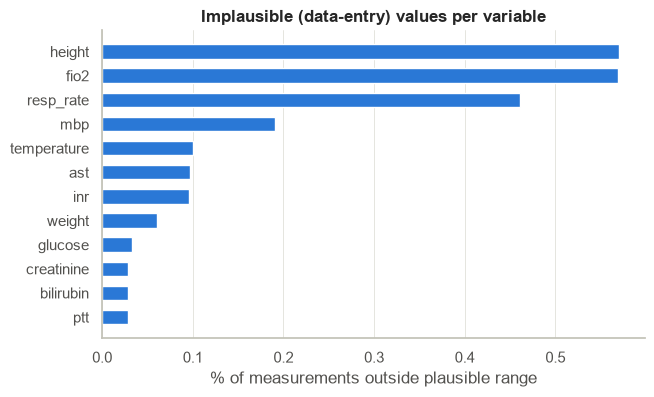

In [21]:
top_out = outlier_report.sort_values("removed_%", ascending=False).head(12)[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top_out.index, top_out["removed_%"], color=C_MAIN, height=0.6)
ax.set_xlabel("% of measurements outside plausible range")
ax.set_title("Implausible (data-entry) values per variable")
ax.grid(axis="y", visible=False)
savefig("02_implausible_values"); plt.show()

## 6. Feature engineering

Each time series is summarised over the first 24 h into **mean / min / max** (the worst value is usually the most
informative in severity scores such as SAPS-II and SOFA) plus a **measurement count**. The count captures *how
intensively* a patient was monitored — itself a signal of clinical concern (informative missingness).

Derived features:
* `gcs_total_min` — sum of the worst eye, verbal and motor scores (3–15).
* `shock_index_max` — max heart rate / min systolic BP.
* `pf_ratio_min` — PaO₂ / FiO₂ (lowest), a marker of respiratory failure (used in SOFA).
* `bun_creatinine_ratio`, `bmi`, `urine_output_ml_kg_h`.
* Binary treatment flags: vasopressors, invasive / non-invasive ventilation.
* Demographic groupings: age band, race group, admission-type group.

In [22]:
SINGLE_VALUE = ["weight", "height"]   # anthropometrics: one value (mean) is enough
series = chart[~chart["variable"].isin(SINGLE_VALUE)]

agg = series.groupby(["stay_id", "variable"])["valuenum"].agg(["mean", "min", "max", "count"]).unstack("variable")
agg.columns = [f"{var}_{stat}" for stat, var in agg.columns]
anthro = chart[chart["variable"].isin(SINGLE_VALUE)].groupby(["stay_id", "variable"])["valuenum"].mean().unstack()

feat = (cohort.set_index("stay_id")
        .join(agg).join(anthro).join(urine).join(vaso).join(vent))

# Counts / treatment flags: absent means "not measured / not given" -> 0
count_cols = [c for c in feat.columns if c.endswith("_count")]
flag_cols = [c for c in feat.columns if c.startswith("vaso_") or c.endswith("_vent")] + ["n_vasopressors"]
for c in ["invasive_vent", "noninvasive_vent"]:
    if c not in feat.columns:
        feat[c] = 0
feat[count_cols + flag_cols] = feat[count_cols + flag_cols].fillna(0)
feat["vasopressor_any"] = (feat["n_vasopressors"] > 0).astype(int)

# GCS components are not summed per time point here; the sum of the worst components is a standard approximation
feat["gcs_total_min"] = feat[["gcs_eye_min", "gcs_verbal_min", "gcs_motor_min"]].sum(axis=1, min_count=3)
feat["shock_index_max"] = feat["heart_rate_max"] / feat["sbp_min"]
feat["pf_ratio_min"] = feat["pao2_min"] / (feat["fio2_max"] / 100)
feat["bun_creatinine_ratio"] = feat["bun_max"] / feat["creatinine_max"]
feat["bmi"] = feat["weight"] / (feat["height"] / 100) ** 2
feat.loc[(feat["bmi"] < 10) | (feat["bmi"] > 80), "bmi"] = np.nan
feat["urine_output_ml_kg_h"] = feat["urine_output_24h"] / feat["weight"] / 24

# Demographic groupings
feat["age_band"] = pd.cut(feat["age"], bins=[17, 40, 55, 65, 75, 85, 200],
                          labels=["18-40", "41-55", "56-65", "66-75", "76-85", ">85"])

def race_group(r):
    r = str(r).upper()
    if "WHITE" in r: return "White"
    if "BLACK" in r: return "Black"
    if "HISPANIC" in r or "LATINO" in r: return "Hispanic/Latino"
    if "ASIAN" in r: return "Asian"
    if any(k in r for k in ["UNKNOWN", "UNABLE", "DECLINED"]): return "Unknown"
    return "Other"

ADM_GROUP = {"EW EMER.": "Emergency", "DIRECT EMER.": "Emergency", "URGENT": "Urgent",
             "ELECTIVE": "Elective/Surgical", "SURGICAL SAME DAY ADMISSION": "Elective/Surgical"}
feat["race_group"] = feat["race"].map(race_group)
feat["admission_group"] = feat["admission_type"].map(ADM_GROUP).fillna("Observation")
top_units = feat["first_careunit"].value_counts().index[:7]
feat["careunit_group"] = feat["first_careunit"].where(feat["first_careunit"].isin(top_units), "Other")
feat["insurance"] = feat["insurance"].fillna("Unknown")
feat["sex_male"] = (feat["gender"] == "M").astype(int)

feat.replace([np.inf, -np.inf], np.nan, inplace=True)
print("Feature table:", feat.shape)
feat.head(3)

Feature table: (51838, 174)


[Output removed before publishing: it showed individual patient rows from MIMIC-IV, which the PhysioNet data-use agreement does not allow to be shared. Re-run this cell locally with credentialed access to see it.]


In [23]:
# Duplicate check on the final analysis table (one row per stay and per patient expected)
print("Duplicate stay_id :", feat.index.duplicated().sum())
print("Duplicate patients:", feat["subject_id"].duplicated().sum())

Duplicate stay_id : 0
Duplicate patients: 0


### 6.1 Leakage control — which columns are *not* allowed as predictors

Some columns are known only **after** the 24 h window or directly encode the outcome. They are kept for EDA but
excluded from the model feature set:

| Column | Why excluded |
|---|---|
| `deathtime`, `dod`, `dischtime`, `outtime`, `hospital_expire_flag` | outcome / end-of-stay information |
| `los` (ICU length of stay) | only known when the patient leaves the ICU (strongly linked to death) |
| `last_careunit`, `n_icu_stays_patient` | future information |
| IDs and raw timestamps | identifiers, not predictors |

In [24]:
NUMERIC_FEATURES = sorted(set(
    [c for c in feat.columns if any(c.endswith(s) for s in ["_mean", "_min", "_max", "_count"])]
    + ["age", "weight", "height", "bmi", "urine_output_24h", "urine_output_ml_kg_h",
       "shock_index_max", "pf_ratio_min", "bun_creatinine_ratio", "n_vasopressors"]))
BINARY_FEATURES = ["sex_male", "vasopressor_any", "invasive_vent", "noninvasive_vent"]
CATEGORICAL_FEATURES = ["admission_group", "insurance", "race_group", "careunit_group"]
TARGET = "mortality"
print(f"{len(NUMERIC_FEATURES)} numeric, {len(BINARY_FEATURES)} binary, {len(CATEGORICAL_FEATURES)} categorical candidates")

135 numeric, 4 binary, 4 categorical candidates


### 6.2 Missing values in the analysis table

Features with no missing values: 33 | with >50% missing: 20


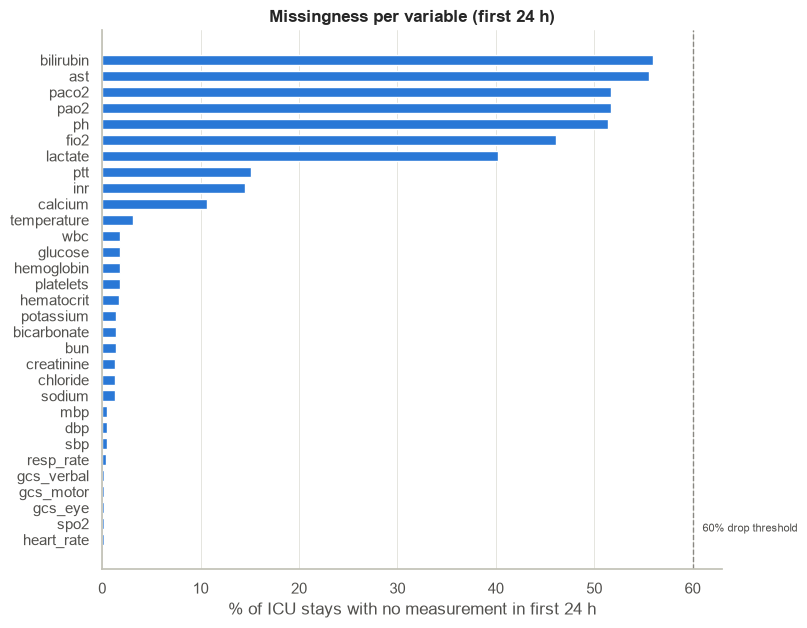

In [25]:
missing_pct = (100 * feat[NUMERIC_FEATURES].isna().mean()).sort_values(ascending=False)
print(f"Features with no missing values: {(missing_pct == 0).sum()} | with >50% missing: {(missing_pct > 50).sum()}")

base_vars = sorted({c.rsplit("_", 1)[0] for c in NUMERIC_FEATURES if c.endswith("_mean")})
miss_var = (100 * feat[[f"{v}_mean" for v in base_vars]].isna().mean()).sort_values()
miss_var.index = [i.replace("_mean", "") for i in miss_var.index]

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(miss_var.index, miss_var.values, color=C_MAIN, height=0.65)
ax.axvline(60, color="#898781", ls="--", lw=1)
ax.text(61, 0.5, "60% drop threshold", color="#52514e", fontsize=8)
ax.set_xlabel("% of ICU stays with no measurement in first 24 h")
ax.set_title("Missingness per variable (first 24 h)")
ax.grid(axis="y", visible=False)
savefig("03_missingness_per_variable"); plt.show()

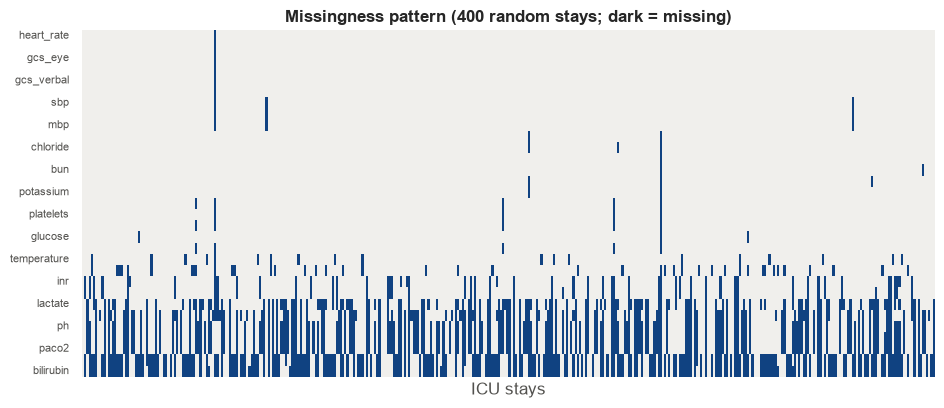

In [26]:
# Missingness pattern matrix (random sample of 400 stays): dark = missing
sample = feat[[f"{v}_mean" for v in miss_var.index]].sample(min(400, len(feat)), random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.heatmap(sample.isna().T.astype(int), cbar=False, cmap=["#f0efec", "#104281"], ax=ax, xticklabels=False)
ax.set_yticklabels([t.get_text().replace("_mean", "") for t in ax.get_yticklabels()], fontsize=8)
ax.set_title(f"Missingness pattern ({len(sample)} random stays; dark = missing)")
ax.set_xlabel("ICU stays")
savefig("04_missingness_matrix"); plt.show()

**Is missingness informative?** If the probability of a test being ordered depends on how sick the patient is, the data
are *Missing Not At Random*. Comparing mortality between stays where a variable **was** vs **was not** measured makes
this visible — and is the reason the protocol prefers *imputation + missingness indicator* over complete-case analysis.

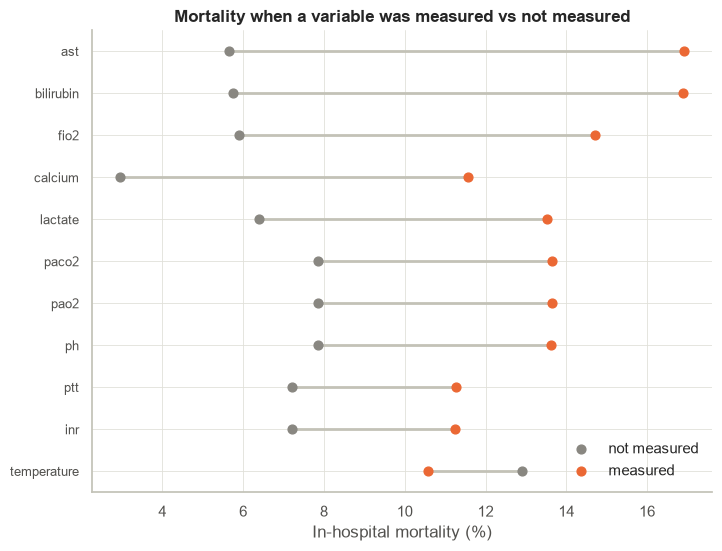

,missing_%,mortality_if_measured_%,mortality_if_missing_%,difference_pp
variable,,,,
ast,55.6,16.9,5.6,11.3
bilirubin,56.0,16.9,5.8,11.1
fio2,46.1,14.7,5.9,8.8
calcium,10.6,11.6,3.0,8.6
lactate,40.2,13.5,6.4,7.1
ph,51.4,13.6,7.9,5.8
paco2,51.7,13.7,7.8,5.8
pao2,51.7,13.7,7.8,5.8
ptt,15.1,11.3,7.2,4.1


In [27]:
rows = []
for v in miss_var.index:
    m = feat[f"{v}_mean"].isna()
    if 0.02 < m.mean() < 0.98:
        rows.append({"variable": v, "missing_%": 100 * m.mean(),
                     "mortality_if_measured_%": 100 * feat.loc[~m, TARGET].mean(),
                     "mortality_if_missing_%": 100 * feat.loc[m, TARGET].mean()})
inf_miss = pd.DataFrame(rows).set_index("variable")
inf_miss["difference_pp"] = inf_miss["mortality_if_measured_%"] - inf_miss["mortality_if_missing_%"]
inf_miss = inf_miss.sort_values("difference_pp")

fig, ax = plt.subplots(figsize=(8, 6))
y = np.arange(len(inf_miss))
ax.hlines(y, inf_miss["mortality_if_missing_%"], inf_miss["mortality_if_measured_%"], color="#c3c2b7", lw=2)
ax.scatter(inf_miss["mortality_if_missing_%"], y, color="#898781", s=40, label="not measured", zorder=3)
ax.scatter(inf_miss["mortality_if_measured_%"], y, color=C_DIED, s=40, label="measured", zorder=3)
ax.set_yticks(y, inf_miss.index, fontsize=9)
ax.set_xlabel("In-hospital mortality (%)")
ax.set_title("Mortality when a variable was measured vs not measured")
ax.legend(loc="lower right")
savefig("05_informative_missingness"); plt.show()
inf_miss.round(1).sort_values("difference_pp", ascending=False).head(10)

In [28]:
# Complete-case analysis: how many patients would survive if we dropped every row with any missing value?
core = [f"{v}_mean" for v in miss_var[miss_var < 60].index]
cc = feat[core].notna().all(axis=1)
print(f"Variables with <60% missing: {len(core)}")
print(f"Complete cases: {cc.sum():,} of {len(feat):,} ({100 * cc.mean():.1f}%)")
print(f"Mortality - complete cases: {100 * feat.loc[cc, TARGET].mean():.2f}% | "
      f"all patients: {100 * feat[TARGET].mean():.2f}%")

Variables with <60% missing: 31
Complete cases: 7,021 of 51,838 (13.5%)
Mortality - complete cases: 27.19% | all patients: 10.65%


## 7. Exploratory Data Analysis

### 7.1 Outcome distribution (class balance)

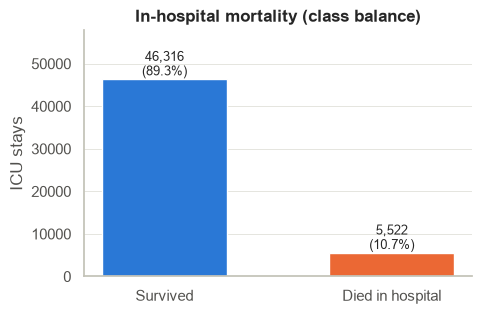

Imbalance ratio (survived : died) = 8.4 : 1


In [29]:
counts = feat[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.bar([OUTCOME_LABELS[i] for i in counts.index], counts.values,
       color=[OUTCOME_PALETTE[i] for i in counts.index], width=0.55)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({100 * v / counts.sum():.1f}%)", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("ICU stays")
ax.set_ylim(0, counts.max() * 1.25)
ax.set_title("In-hospital mortality (class balance)")
ax.grid(axis="x", visible=False)
savefig("06_outcome_balance"); plt.show()
print(f"Imbalance ratio (survived : died) = {counts[0] / counts[1]:.1f} : 1")

### 7.2 Mortality across patient subgroups (fairness dimension, RQ6)
Bars show mortality with 95 % Wilson confidence intervals; the dashed line is the overall cohort mortality.

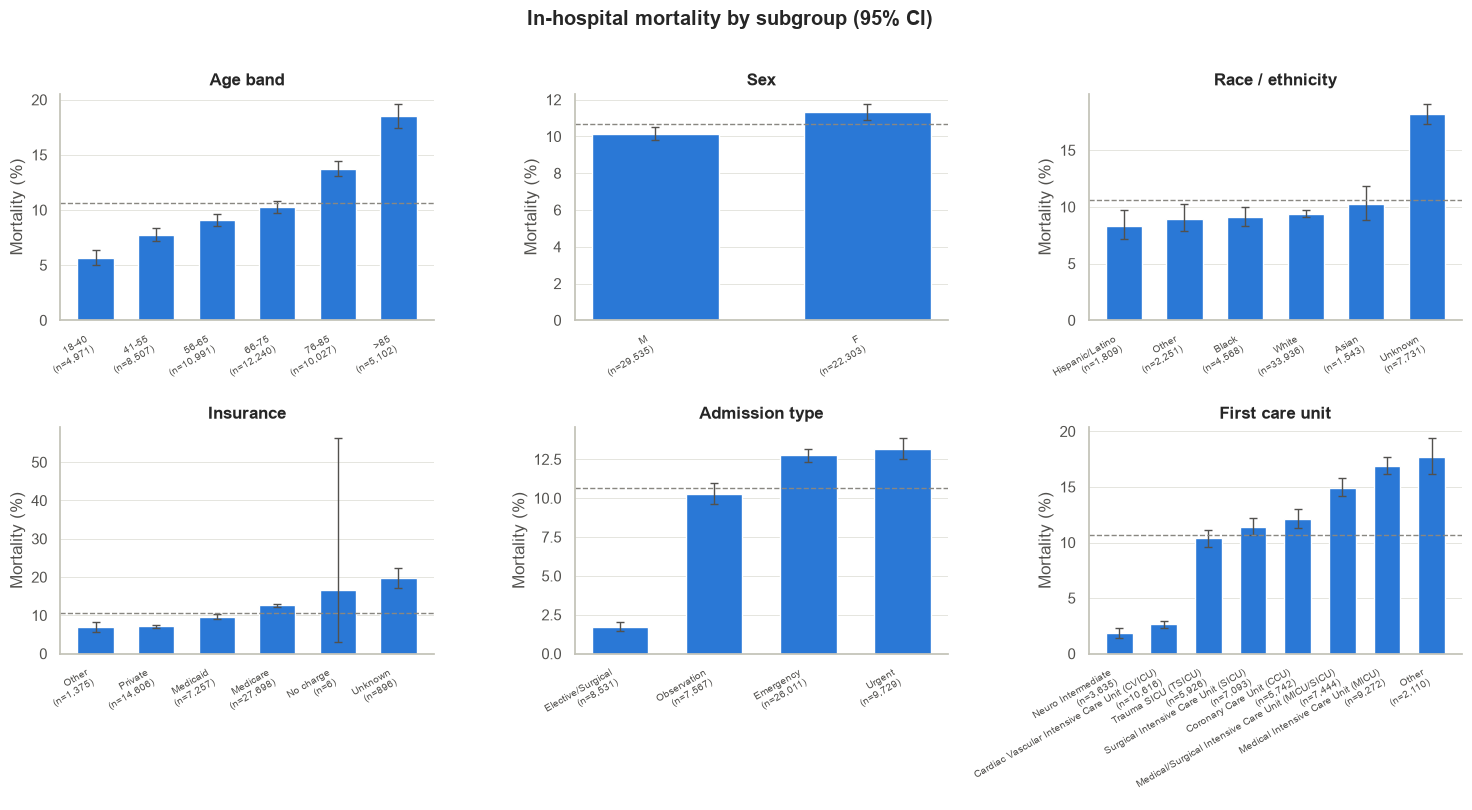

In [30]:
def subgroup_table(col):
    g = feat.groupby(col, observed=True)[TARGET].agg(["sum", "count"])
    g["mortality_%"] = 100 * g["sum"] / g["count"]
    ci = g.apply(lambda r: wilson_ci(r["sum"], r["count"]), axis=1, result_type="expand") * 100
    g["ci_low"], g["ci_high"] = ci[0], ci[1]
    return g

SUBGROUPS = [("age_band", "Age band"), ("gender", "Sex"), ("race_group", "Race / ethnicity"),
             ("insurance", "Insurance"), ("admission_group", "Admission type"), ("careunit_group", "First care unit")]
overall = 100 * feat[TARGET].mean()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
subgroup_results = {}
for ax, (col, title) in zip(axes.ravel(), SUBGROUPS):
    g = subgroup_table(col)
    if col != "age_band":
        g = g.sort_values("mortality_%")
    subgroup_results[col] = g
    x = np.arange(len(g))
    ax.bar(x, g["mortality_%"], color=C_MAIN, width=0.6,
           yerr=[g["mortality_%"] - g["ci_low"], g["ci_high"] - g["mortality_%"]],
           error_kw={"ecolor": "#52514e", "elinewidth": 1, "capsize": 3})
    ax.axhline(overall, color="#898781", ls="--", lw=1)
    ax.set_xticks(x, [f"{i}\n(n={n:,})" for i, n in zip(g.index, g["count"])], fontsize=7.5, rotation=30, ha="right")
    ax.set_title(title)
    ax.set_ylabel("Mortality (%)")
    ax.grid(axis="x", visible=False)
fig.suptitle("In-hospital mortality by subgroup (95% CI)", fontweight="bold", y=1.01)
plt.tight_layout()
savefig("07_subgroup_mortality"); plt.show()

In [31]:
# Chi-square tests: is mortality associated with each subgroup variable?
chi_rows = []
for col, title in SUBGROUPS:
    ct = pd.crosstab(feat[col], feat[TARGET])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    n = ct.values.sum()
    cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
    chi_rows.append({"variable": title, "chi2": round(chi2, 1), "dof": dof, "p_value": p, "cramers_v": round(cramers_v, 3)})
pd.DataFrame(chi_rows).set_index("variable")

,chi2,dof,p_value,cramers_v
variable,,,,
Age band,664.0,5,2.944391e-141,0.113
Sex,18.0,1,2.168273e-05,0.019
Race / ethnicity,542.1,5,6.364288e-115,0.102
Insurance,412.4,5,6.319112e-87,0.089
Admission type,904.0,3,1.204673e-195,0.132
First care unit,1666.3,7,0.000000e+00,0.179


### 7.3 Age

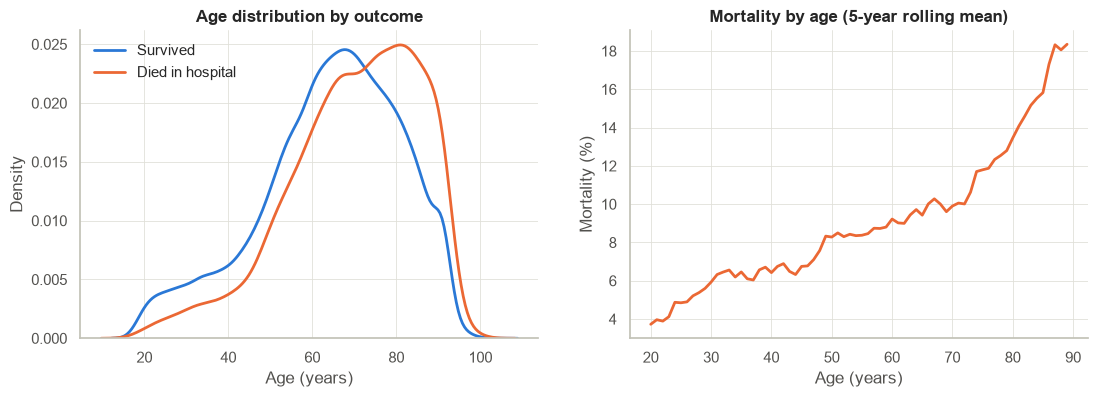

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for k in [0, 1]:
    sns.kdeplot(feat.loc[feat[TARGET] == k, "age"], ax=axes[0], color=OUTCOME_PALETTE[k],
                label=OUTCOME_LABELS[k], lw=2, common_norm=False)
axes[0].set_title("Age distribution by outcome"); axes[0].set_xlabel("Age (years)"); axes[0].legend()

# Mortality by single year of age, smoothed
by_age = feat.groupby(feat["age"].clip(18, 91).round())[TARGET].mean().rolling(5, center=True).mean() * 100
axes[1].plot(by_age.index, by_age.values, color=C_DIED, lw=2)
axes[1].set_title("Mortality by age (5-year rolling mean)")
axes[1].set_xlabel("Age (years)"); axes[1].set_ylabel("Mortality (%)")
savefig("08_age"); plt.show()

### 7.4 Temporal drift — `anchor_year_group`
MIMIC-IV shifts every patient's dates, so true calendar time is unavailable; `anchor_year_group` (3-year bins) is the
only time-aware field (protocol §6). Changes across groups indicate **population/practice drift**, which matters for
temporal validation (RQ3).

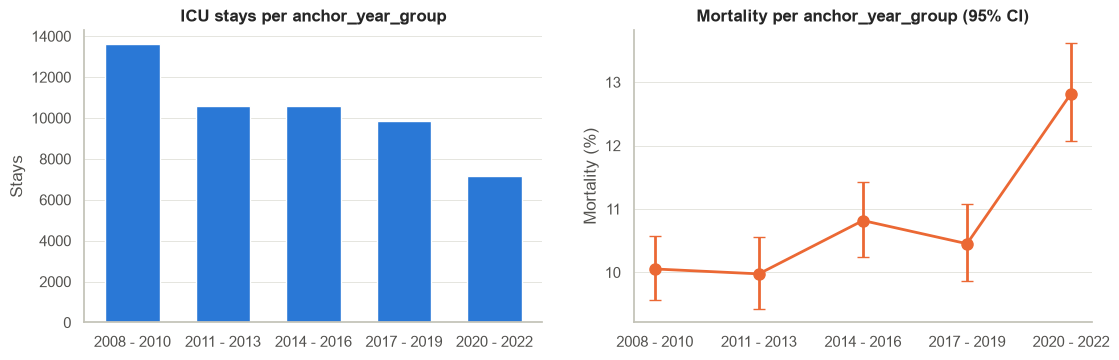

,count,mortality_%
anchor_year_group,,
2008 - 2010,13627,10.05
2011 - 2013,10575,9.98
2014 - 2016,10594,10.82
2017 - 2019,9874,10.45
2020 - 2022,7168,12.82


In [33]:
yg = subgroup_table("anchor_year_group")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(yg.index, yg["count"], color=C_MAIN, width=0.6)
axes[0].set_title("ICU stays per anchor_year_group"); axes[0].set_ylabel("Stays")
axes[1].errorbar(yg.index, yg["mortality_%"], yerr=[yg["mortality_%"] - yg["ci_low"], yg["ci_high"] - yg["mortality_%"]],
                 color=C_DIED, lw=2, marker="o", ms=8, capsize=4)
axes[1].set_title("Mortality per anchor_year_group (95% CI)"); axes[1].set_ylabel("Mortality (%)")
for ax in axes: ax.grid(axis="x", visible=False)
savefig("09_temporal_drift"); plt.show()
yg[["count", "mortality_%"]].round(2)

### 7.5 Physiology in the first 24 h: survivors vs non-survivors
Distributions are clipped to the 1st–99th percentile for display only.

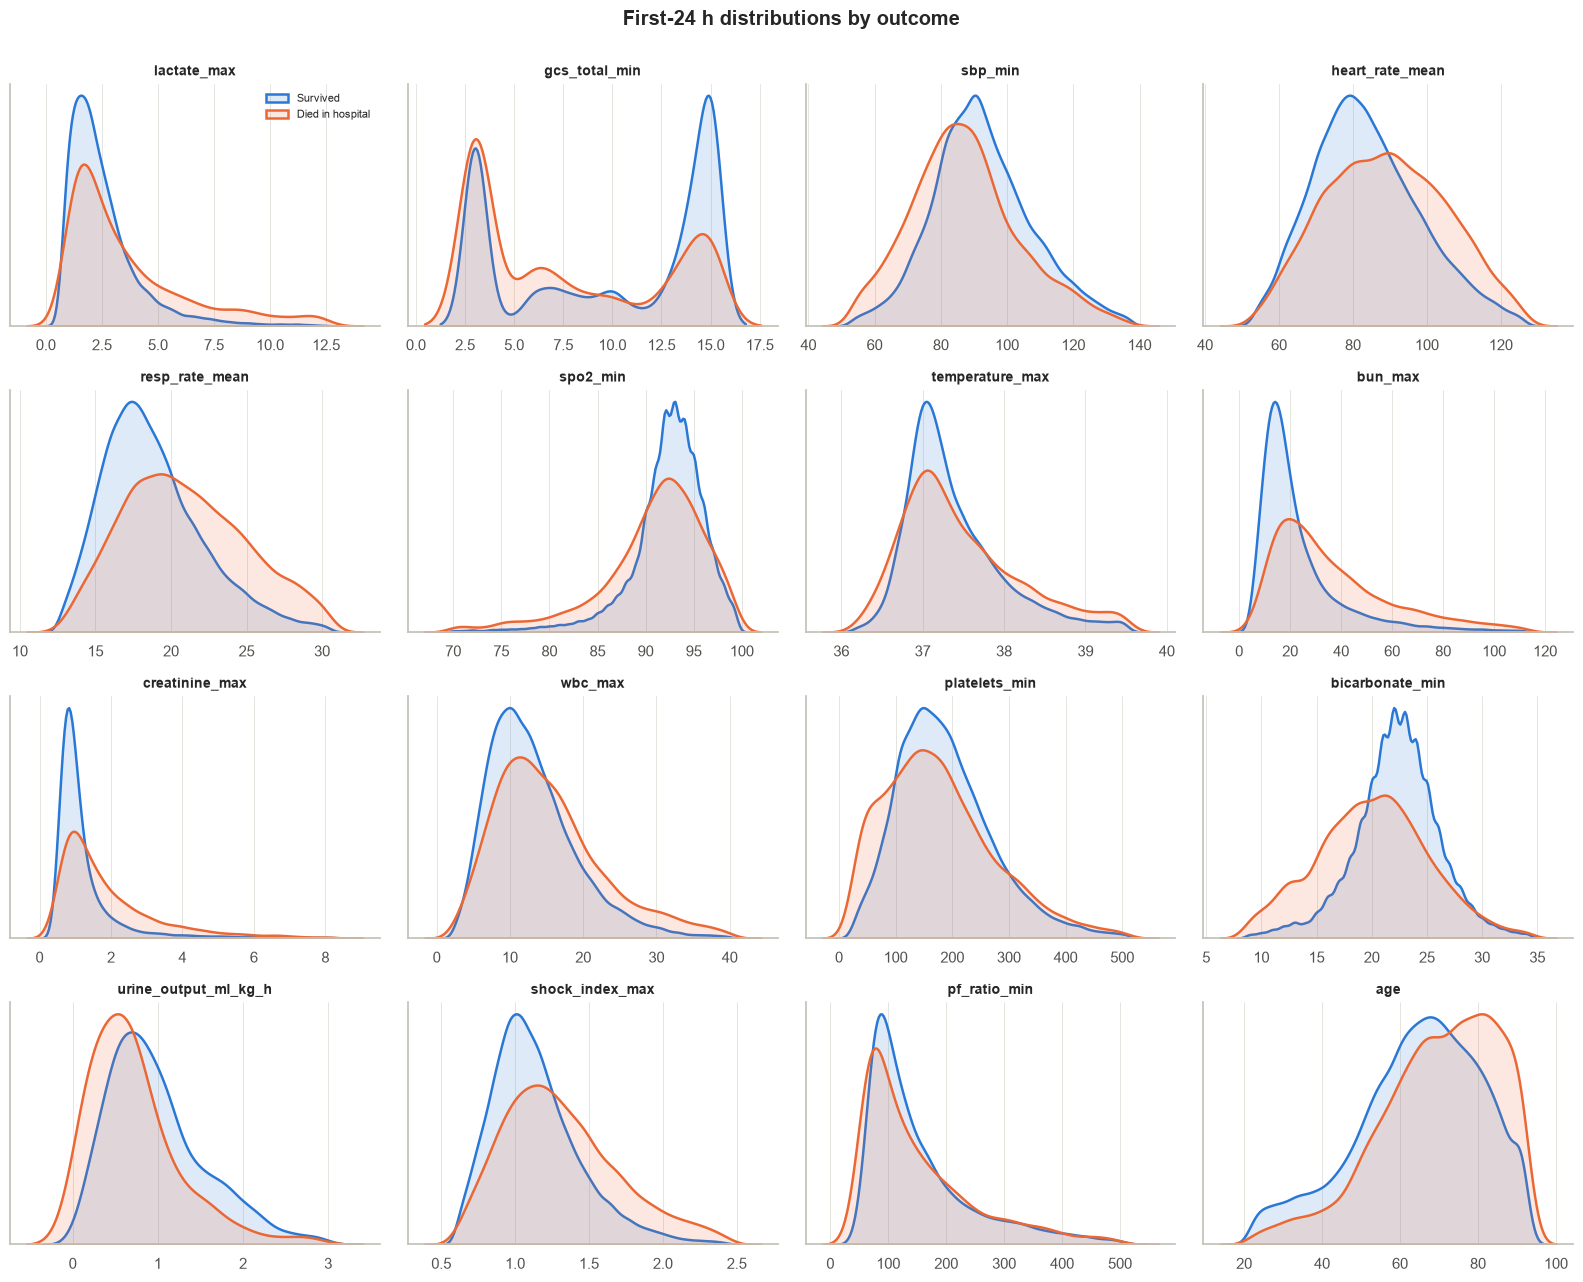

In [34]:
KEY = ["lactate_max", "gcs_total_min", "sbp_min", "heart_rate_mean", "resp_rate_mean", "spo2_min",
       "temperature_max", "bun_max", "creatinine_max", "wbc_max", "platelets_min", "bicarbonate_min",
       "urine_output_ml_kg_h", "shock_index_max", "pf_ratio_min", "age"]
KEY = [k for k in KEY if k in feat.columns]

ncols = 4
nrows = int(np.ceil(len(KEY) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.2 * nrows))
for ax, col in zip(axes.ravel(), KEY):
    s = feat[[col, TARGET]].dropna()
    lo_q, hi_q = s[col].quantile([0.01, 0.99])
    s = s[(s[col] >= lo_q) & (s[col] <= hi_q)]
    for k in [0, 1]:
        sns.kdeplot(s.loc[s[TARGET] == k, col], ax=ax, color=OUTCOME_PALETTE[k], lw=1.8,
                    fill=True, alpha=0.15, label=OUTCOME_LABELS[k], warn_singular=False)
    ax.set_title(col, fontsize=10); ax.set_xlabel(""); ax.set_ylabel("")
    ax.set_yticks([])
for ax in axes.ravel()[len(KEY):]:
    ax.axis("off")
axes.ravel()[0].legend(fontsize=8)
fig.suptitle("First-24 h distributions by outcome", fontweight="bold", y=1.0)
plt.tight_layout()
savefig("10_physiology_by_outcome"); plt.show()

In [35]:
# Summary statistics by outcome with Mann-Whitney U test
rows = []
for col in KEY:
    a = feat.loc[feat[TARGET] == 0, col].dropna()
    b = feat.loc[feat[TARGET] == 1, col].dropna()
    if len(a) == 0 or len(b) == 0:
        continue
    u, p = stats.mannwhitneyu(a, b)
    rows.append({"feature": col, "median_survived": a.median(), "median_died": b.median(),
                 "IQR_survived": f"{a.quantile(.25):.2f}-{a.quantile(.75):.2f}",
                 "IQR_died": f"{b.quantile(.25):.2f}-{b.quantile(.75):.2f}", "p_value": p})
pd.DataFrame(rows).set_index("feature").round(3)

,median_survived,median_died,IQR_survived,IQR_died,p_value
feature,,,,,
lactate_max,2.100,2.800,1.40-3.10,1.70-5.20,0.000
gcs_total_min,12.000,6.000,3.00-15.00,3.00-13.00,0.000
sbp_min,91.000,85.000,82.00-102.00,75.00-96.00,0.000
heart_rate_mean,82.289,89.133,73.16-93.11,76.71-102.03,0.000
resp_rate_mean,18.250,20.719,16.33-20.71,17.87-24.19,0.000
spo2_min,93.000,92.000,91.00-95.00,88.00-95.00,0.000
temperature_max,37.222,37.278,36.94-37.67,36.89-37.89,0.019
bun_max,18.000,30.000,13.00-27.00,19.00-50.00,0.000
creatinine_max,0.900,1.400,0.70-1.30,0.90-2.40,0.000


### 7.6 Outliers that remain after the plausibility filter
Values inside the plausible range can still be extreme. The IQR rule (outside Q1 − 3·IQR, Q3 + 3·IQR) counts these
*statistical* outliers; they are mostly real, very sick patients, so they are **kept** and later winsorised rather than
deleted.

Features with the most extreme (3*IQR) values:


,% extreme
gcs_eye_max,15.76
gcs_motor_max,11.61
ast_max,10.27
ast_mean,9.88
ptt_max,9.16
ast_min,9.10
bilirubin_max,8.95
bilirubin_mean,8.37
bilirubin_min,8.04
ptt_mean,7.30


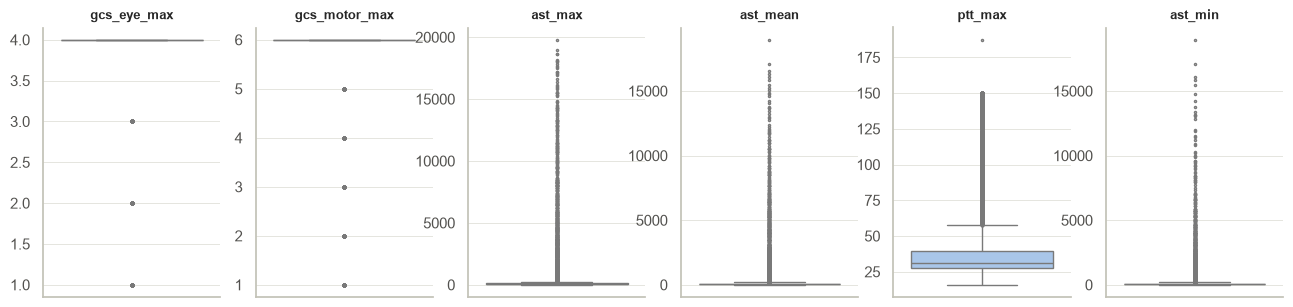

In [36]:
def iqr_outlier_pct(s, k=3.0):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return 100 * ((s < q1 - k * iqr) | (s > q3 + k * iqr)).mean()

iqr_tab = pd.Series({c: iqr_outlier_pct(feat[c]) for c in NUMERIC_FEATURES if not c.endswith("_count")})
iqr_tab = iqr_tab.sort_values(ascending=False)
print("Features with the most extreme (3*IQR) values:")
display(iqr_tab.head(10).round(2).to_frame("% extreme"))

box_cols = iqr_tab.index[:6]
fig, axes = plt.subplots(1, 6, figsize=(16, 3.5))
for ax, col in zip(axes, box_cols):
    sns.boxplot(y=feat[col], ax=ax, color="#9ec5f4", fliersize=1.5, linewidth=1)
    ax.set_title(col, fontsize=9); ax.set_ylabel("")
savefig("11_extreme_values_boxplots"); plt.show()

### 7.7 Correlation structure

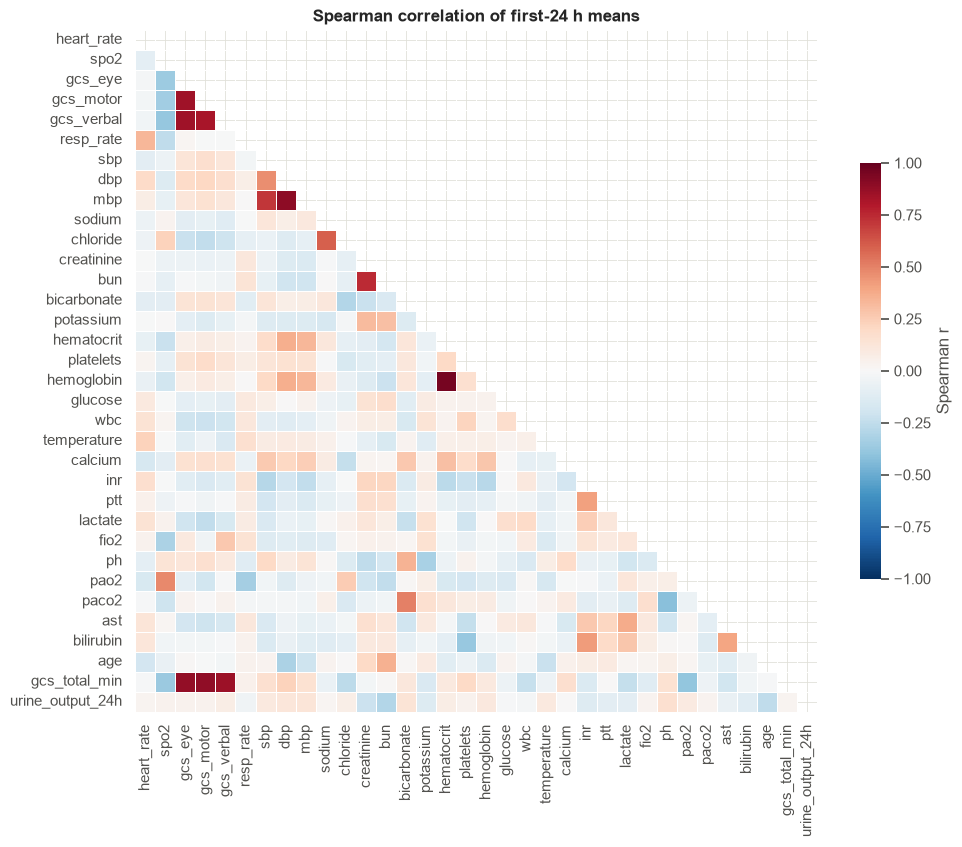

,level_0,level_1,r,abs_r
593,hemoglobin,hematocrit,0.960,0.960
279,mbp,dbp,0.892,0.892
1091,gcs_total_min,gcs_motor,0.888,0.888
1090,gcs_total_min,gcs_eye,0.882,0.882
1092,gcs_total_min,gcs_verbal,0.857,0.857
104,gcs_motor,gcs_eye,0.846,0.846
138,gcs_verbal,gcs_eye,0.844,0.844
139,gcs_verbal,gcs_motor,0.821,0.821
419,bun,creatinine,0.745,0.745
278,mbp,sbp,0.716,0.716


In [37]:
corr_cols = [f"{v}_mean" for v in miss_var[miss_var < 60].index] + ["age", "gcs_total_min", "urine_output_24h"]
corr = feat[corr_cols].corr(method="spearman")
corr.index = corr.columns = [c.replace("_mean", "") for c in corr.columns]
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.5, linecolor="white", cbar_kws={"shrink": 0.6, "label": "Spearman r"}, ax=ax)
ax.set_title("Spearman correlation of first-24 h means")
savefig("12_correlation_heatmap"); plt.show()

pairs = corr.where(~mask).stack().rename("r").reset_index()
pairs["abs_r"] = pairs["r"].abs()
pairs.sort_values("abs_r", ascending=False).head(10).round(3)

### 7.8 Univariate discrimination (AUROC of each feature alone)
An AUROC of 0.5 means no signal; values far below 0.5 mean the feature is *inversely* related to death. We plot
`max(AUROC, 1 − AUROC)` with the direction shown by colour.

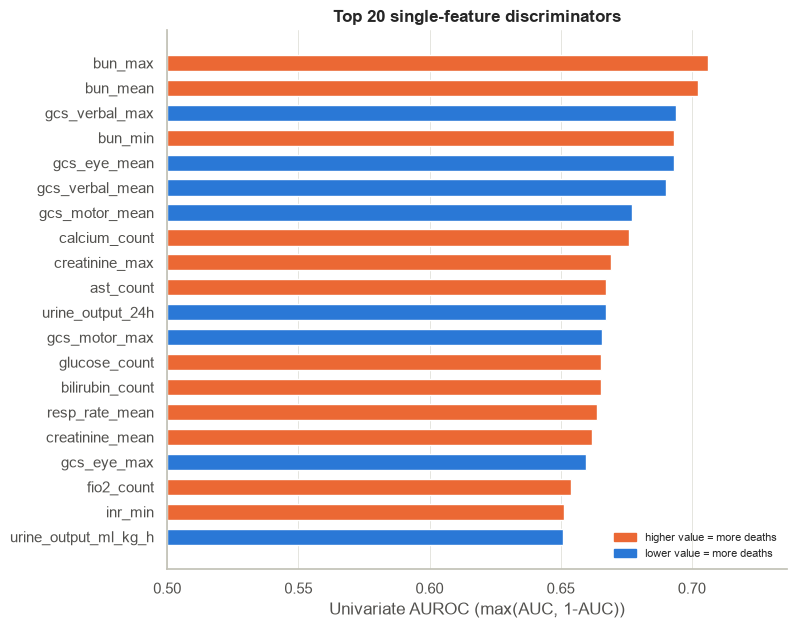

,auroc,strength,direction,n_observed
feature,,,,
bun_max,0.706,0.706,higher = more deaths,51127
bun_mean,0.702,0.702,higher = more deaths,51127
gcs_verbal_max,0.306,0.694,lower = more deaths,51740
bun_min,0.693,0.693,higher = more deaths,51127
gcs_eye_mean,0.307,0.693,lower = more deaths,51749
gcs_verbal_mean,0.310,0.690,lower = more deaths,51740
gcs_motor_mean,0.323,0.677,lower = more deaths,51742
calcium_count,0.676,0.676,higher = more deaths,51838
creatinine_max,0.669,0.669,higher = more deaths,51139


In [38]:
uni = []
for c in NUMERIC_FEATURES + BINARY_FEATURES:
    s = feat[[c, TARGET]].dropna()
    if s[c].nunique() > 1 and s[TARGET].nunique() == 2:
        auc = roc_auc_score(s[TARGET], s[c])
        uni.append({"feature": c, "auroc": auc, "strength": max(auc, 1 - auc),
                    "direction": "higher = more deaths" if auc >= 0.5 else "lower = more deaths",
                    "n_observed": len(s)})
uni = pd.DataFrame(uni).sort_values("strength", ascending=False).set_index("feature")

top = uni.head(20)[::-1]
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top.index, top["strength"] - 0.5, left=0.5, height=0.65,
        color=[C_DIED if d.startswith("higher") else C_SURV for d in top["direction"]])
ax.set_xlim(0.5, top["strength"].max() + 0.03)
ax.set_xlabel("Univariate AUROC (max(AUC, 1-AUC))")
ax.set_title("Top 20 single-feature discriminators")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=C_DIED, label="higher value = more deaths"),
                   Patch(color=C_SURV, label="lower value = more deaths")], loc="lower right", fontsize=8)
ax.grid(axis="y", visible=False)
savefig("13_univariate_auroc"); plt.show()
uni.head(15).round(3)

### 7.9 Monitoring intensity and treatments

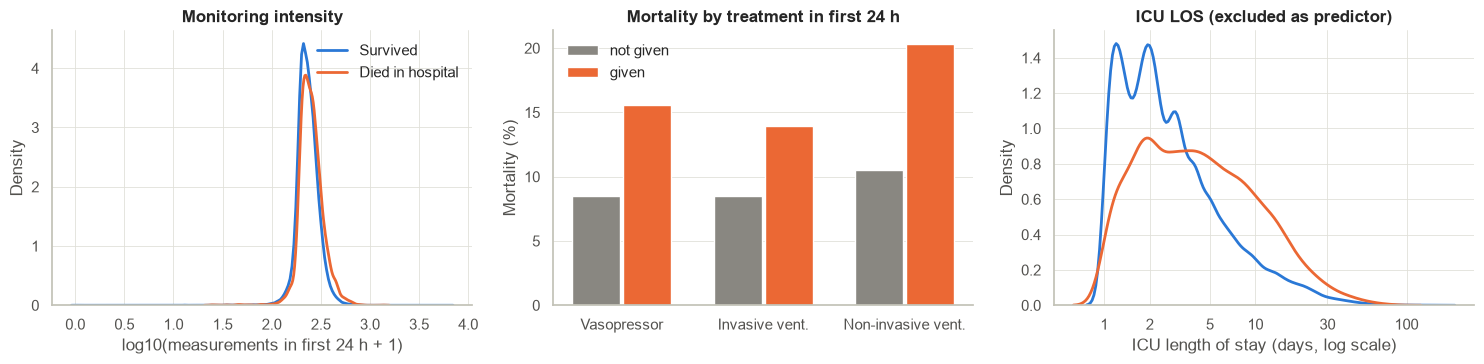

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
# measurements per stay
n_meas = feat[count_cols].sum(axis=1)
for k in [0, 1]:
    sns.kdeplot(np.log10(n_meas[feat[TARGET] == k] + 1), ax=axes[0], color=OUTCOME_PALETTE[k], lw=2,
                label=OUTCOME_LABELS[k])
axes[0].set_xlabel("log10(measurements in first 24 h + 1)"); axes[0].set_title("Monitoring intensity"); axes[0].legend()

# treatments
treat = pd.DataFrame({t: feat.groupby(t)[TARGET].mean() * 100
                      for t in ["vasopressor_any", "invasive_vent", "noninvasive_vent"]}).T
treat.columns = ["not given", "given"]
x = np.arange(len(treat))
axes[1].bar(x - 0.18, treat["not given"], 0.34, color="#898781", label="not given")
axes[1].bar(x + 0.18, treat["given"], 0.34, color=C_DIED, label="given")
axes[1].set_xticks(x, ["Vasopressor", "Invasive vent.", "Non-invasive vent."])
axes[1].set_ylabel("Mortality (%)"); axes[1].set_title("Mortality by treatment in first 24 h"); axes[1].legend()
axes[1].grid(axis="x", visible=False)

# ICU length of stay (EDA only - NOT a predictor)
for k in [0, 1]:
    sns.kdeplot(np.log10(feat.loc[feat[TARGET] == k, "los"]), ax=axes[2], color=OUTCOME_PALETTE[k], lw=2,
                label=OUTCOME_LABELS[k])
axes[2].set_xticks(np.log10([1, 2, 5, 10, 30, 100]), [1, 2, 5, 10, 30, 100])
axes[2].set_xlabel("ICU length of stay (days, log scale)"); axes[2].set_title("ICU LOS (excluded as predictor)")
plt.tight_layout()
savefig("14_monitoring_treatments_los"); plt.show()

## 8. Preprocessing and transformations (train-only fit)

To avoid **leakage**, every statistic used for preprocessing (medians, percentiles, scaling, selected columns) is
learned on the **training set only** and then applied unchanged to the test set.

1. **Patient-grouped, stratified split (80/20)** with `StratifiedGroupKFold` grouped by `subject_id` — no patient
   appears in both sets and the mortality rate is preserved.
2. **Drop** numeric features with > 60 % missing in train.
3. **Log-transform** strongly right-skewed non-negative features (|skew| > 2 in train), e.g. creatinine, lactate.
4. **Winsorise** at the train 1st/99th percentiles.
5. **Missing-value indicators** + **median imputation** (protocol: *imputation plus indicator*).
6. **One-hot encode** categorical variables (categories learned from train).
7. **Standardise** numeric features (train mean / sd).

In [40]:
model_df = feat[NUMERIC_FEATURES + BINARY_FEATURES + CATEGORICAL_FEATURES + [TARGET, "subject_id"]].copy()

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(sgkf.split(model_df, model_df[TARGET], groups=model_df["subject_id"]))
train_df, test_df = model_df.iloc[train_idx].copy(), model_df.iloc[test_idx].copy()

print(f"Train: {len(train_df):,} stays, mortality {100 * train_df[TARGET].mean():.2f}%")
print(f"Test : {len(test_df):,} stays, mortality {100 * test_df[TARGET].mean():.2f}%")
print("Patients in both sets:", len(set(train_df["subject_id"]) & set(test_df["subject_id"])))

Train: 41,470 stays, mortality 10.65%
Test : 10,368 stays, mortality 10.65%
Patients in both sets: 0


In [41]:
class TrainOnlyPreprocessor:
    # Learns every transformation parameter from the training data only

    def __init__(self, numeric, binary, categorical, max_missing=0.60, skew_threshold=2.0, clip_q=(0.01, 0.99)):
        self.numeric, self.binary, self.categorical = list(numeric), list(binary), list(categorical)
        self.max_missing, self.skew_threshold, self.clip_q = max_missing, skew_threshold, clip_q

    def fit(self, df):
        miss = df[self.numeric].isna().mean()
        self.dropped_missing_ = miss[miss > self.max_missing].index.tolist()
        self.num_ = [c for c in self.numeric if c not in self.dropped_missing_]
        x = df[self.num_]
        skew = x.skew()
        self.log_cols_ = [c for c in self.num_ if abs(skew[c]) > self.skew_threshold and x[c].min() >= 0]
        x = self._log(x.copy())
        self.lo_, self.hi_ = x.quantile(self.clip_q[0]), x.quantile(self.clip_q[1])
        x = x.clip(self.lo_, self.hi_, axis=1)
        self.indicator_cols_ = [c for c in self.num_ if df[c].isna().any()]
        self.median_ = x.median()
        x = x.fillna(self.median_)
        self.mean_, self.std_ = x.mean(), x.std().replace(0, 1)
        self.categories_ = {c: sorted(df[c].astype(str).unique()) for c in self.categorical}
        return self

    def _log(self, x):
        for c in self.log_cols_:
            x[c] = np.log1p(x[c])
        return x

    def transform(self, df):
        x = self._log(df[self.num_].copy())
        x = x.clip(self.lo_, self.hi_, axis=1)
        ind = df[self.indicator_cols_].isna().astype(int).add_suffix("_missing")
        x = (x.fillna(self.median_) - self.mean_) / self.std_
        x = x.rename(columns={c: f"log_{c}" for c in self.log_cols_})
        cats = [pd.DataFrame({f"{c}={v}": (df[c].astype(str) == v).astype(int) for v in self.categories_[c]},
                             index=df.index) for c in self.categorical]
        return pd.concat([x, ind, df[self.binary].astype(int), *cats], axis=1)

    def fit_transform(self, df):
        return self.fit(df).transform(df)

prep = TrainOnlyPreprocessor(NUMERIC_FEATURES, BINARY_FEATURES, CATEGORICAL_FEATURES)
X_train = prep.fit_transform(train_df)
X_test = prep.transform(test_df)
y_train, y_test = train_df[TARGET].values, test_df[TARGET].values

print("Dropped (>60% missing):", len(prep.dropped_missing_), prep.dropped_missing_[:12], "...")
print("Log-transformed       :", len(prep.log_cols_), prep.log_cols_[:12], "...")
print("Missing indicators    :", len(prep.indicator_cols_))
print("X_train:", X_train.shape, "| X_test:", X_test.shape,
      "| any NaN left:", bool(X_train.isna().any().any() or X_test.isna().any().any()))

Dropped (>60% missing): 4 ['bmi', 'height', 'urine_output_ml_kg_h', 'weight'] ...
Log-transformed       : 50 ['ast_max', 'ast_mean', 'ast_min', 'bilirubin_max', 'bilirubin_mean', 'bilirubin_min', 'bun_creatinine_ratio', 'bun_max', 'bun_mean', 'bun_min', 'creatinine_max', 'creatinine_mean'] ...
Missing indicators    : 98
X_train: (41470, 257) | X_test: (10368, 257) | any NaN left: False


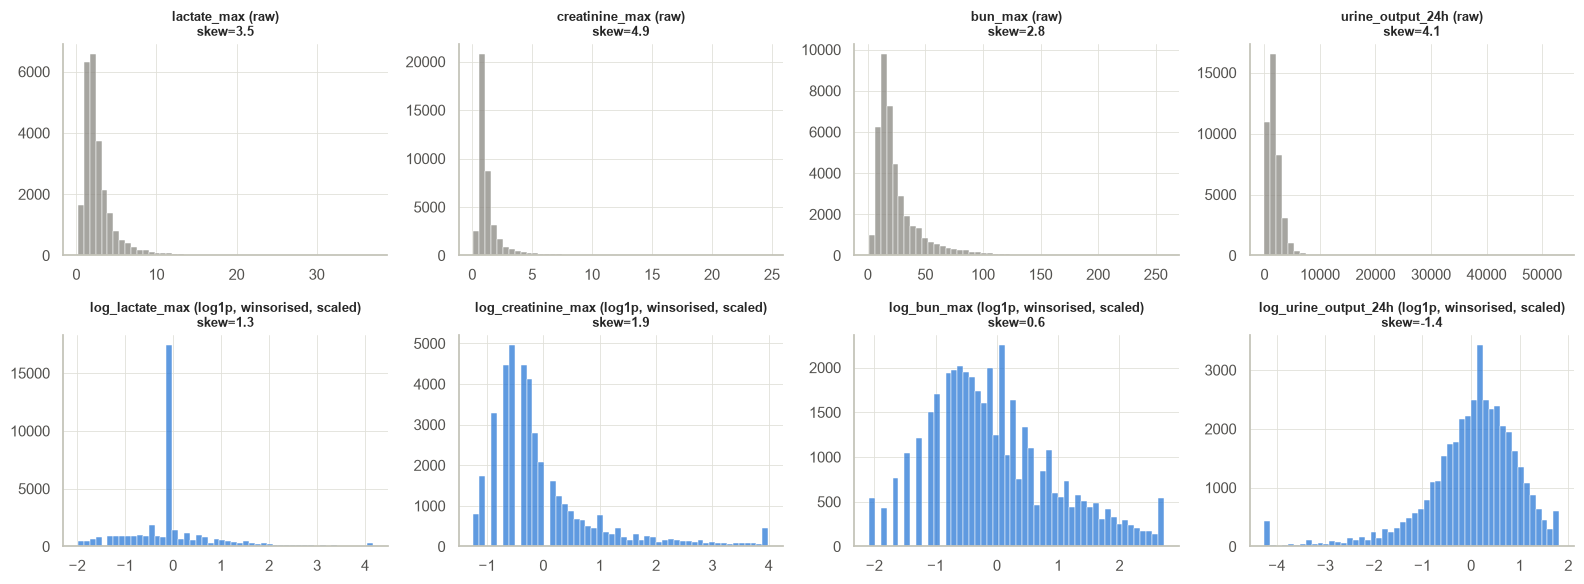

In [42]:
# Effect of the log transform + winsorising on skewness (train set)
show = [c for c in ["lactate_max", "creatinine_max", "bun_max", "urine_output_24h"] if c in prep.log_cols_]
if show:
    fig, axes = plt.subplots(2, len(show), figsize=(4 * len(show), 6), squeeze=False)
    for j, c in enumerate(show):
        sns.histplot(train_df[c].dropna(), ax=axes[0, j], color="#898781", bins=50)
        axes[0, j].set_title(f"{c} (raw)\nskew={train_df[c].skew():.1f}", fontsize=9)
        sns.histplot(X_train[f"log_{c}"], ax=axes[1, j], color=C_MAIN, bins=50)
        axes[1, j].set_title(f"log_{c} (log1p, winsorised, scaled)\nskew={X_train[f'log_{c}'].skew():.1f}", fontsize=9)
        for ax in axes[:, j]: ax.set_xlabel(""); ax.set_ylabel("")
    plt.tight_layout()
    savefig("15_transformations"); plt.show()

## 9. Feature selection (training data only)

A three-stage filter keeps a compact, non-redundant feature set:

1. **Near-zero variance:** drop features where one value covers > 99 % of rows.
2. **Redundancy:** for pairs with |Pearson r| > 0.95, drop the one with the lower univariate AUROC.
3. **Relevance:** rank by **mutual information** and **XGBoost gain** (on GPU when available); keep features in the
   top-K of the combined rank.

The selection is checked with 5-fold grouped cross-validation **on the training set** (the test set stays untouched for
the later calibration case study).

In [43]:
# Stage 1: near-zero variance
dominant_share = X_train.apply(lambda s: s.value_counts(normalize=True).iloc[0])
nzv = dominant_share[dominant_share > 0.99].index.tolist()
X1 = X_train.drop(columns=nzv)
print(f"Stage 1 - near-zero variance removed: {len(nzv)}")

# Stage 2: redundancy (|r| > 0.95)
uni_train = {c: abs(roc_auc_score(y_train, X1[c]) - 0.5) for c in X1.columns}
corr_abs = X1.corr().abs()
upper = corr_abs.where(np.triu(np.ones(corr_abs.shape, dtype=bool), k=1))
to_drop = set()
for a, b in upper.stack()[lambda s: s > 0.95].index:
    if a not in to_drop and b not in to_drop:
        to_drop.add(a if uni_train[a] < uni_train[b] else b)
X2 = X1.drop(columns=sorted(to_drop))
print(f"Stage 2 - redundant (|r|>0.95) removed : {len(to_drop)}")
print("Remaining:", X2.shape[1])

Stage 1 - near-zero variance removed: 30


Stage 2 - redundant (|r|>0.95) removed : 90
Remaining: 137


In [44]:
# Stage 3: relevance - mutual information + XGBoost gain importance
mi = pd.Series(mutual_info_classif(X2, y_train, random_state=RANDOM_STATE), index=X2.columns)

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
xgb_params = dict(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                  tree_method="hist", device=XGB_DEVICE, eval_metric="aucpr",
                  scale_pos_weight=pos_weight, random_state=RANDOM_STATE)
t0 = time.time()
xgb_sel = xgb.XGBClassifier(**xgb_params).fit(X2, y_train)
print(f"XGBoost trained on {XGB_DEVICE.upper()} in {time.time() - t0:.1f}s")
gain = pd.Series(xgb_sel.get_booster().get_score(importance_type="gain")).reindex(X2.columns).fillna(0)

ranking = pd.DataFrame({"mutual_info": mi, "xgb_gain": gain})
ranking["rank_mi"] = ranking["mutual_info"].rank(ascending=False)
ranking["rank_gain"] = ranking["xgb_gain"].rank(ascending=False)
ranking["mean_rank"] = ranking[["rank_mi", "rank_gain"]].mean(axis=1)
ranking = ranking.sort_values("mean_rank")

TOP_K = 40
selected = ranking.index[:TOP_K].tolist()
print(f"Stage 3 - selected top {TOP_K} by combined rank")
ranking.head(15).round(4)

XGBoost trained on CPU in 5.4s
Stage 3 - selected top 40 by combined rank


,mutual_info,xgb_gain,rank_mi,rank_gain,mean_rank
log_gcs_motor_max,0.0415,646.4691,1.0,3.0,2.0
gcs_verbal_max,0.0327,2138.3701,6.0,1.0,3.5
gcs_eye_mean,0.0378,250.7312,3.0,6.0,4.5
log_bun_max,0.0276,376.0479,8.0,4.0,6.0
ast_max_missing,0.0245,717.9747,11.0,2.0,6.5
log_urine_output_24h,0.0277,144.1824,7.0,12.0,9.5
ast_count,0.0210,193.4817,15.0,9.0,12.0
log_gcs_eye_max,0.0377,88.1205,4.0,22.0,13.0
log_ast_mean,0.0252,88.7387,9.0,21.0,15.0
resp_rate_mean,0.0183,156.5544,21.0,11.0,16.0


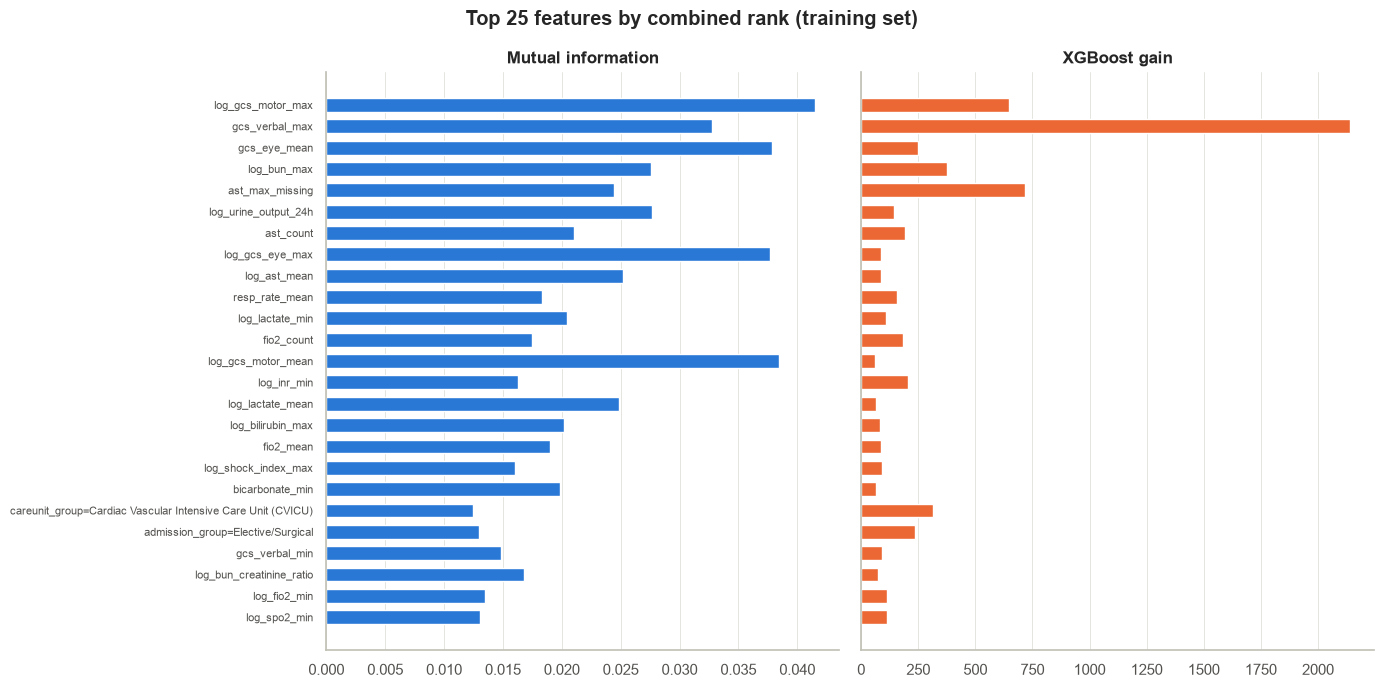

In [45]:
top = ranking.head(25)[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)
axes[0].barh(top.index, top["mutual_info"], color=C_MAIN, height=0.65); axes[0].set_title("Mutual information")
axes[1].barh(top.index, top["xgb_gain"], color=C_DIED, height=0.65); axes[1].set_title("XGBoost gain")
for ax in axes: ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Top 25 features by combined rank (training set)", fontweight="bold")
plt.tight_layout()
savefig("16_feature_importance"); plt.show()

In [46]:
# Sanity check: does the reduced feature set keep the signal? (5-fold grouped CV on TRAIN only)
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
groups = train_df["subject_id"].values

def cv_scores(make_model, X):
    # Explicit CV loop (works with any sklearn/xgboost version combination)
    aurocs, auprcs = [], []
    for tr, va in cv.split(X, y_train, groups=groups):
        model = make_model().fit(X.iloc[tr], y_train[tr])
        p = model.predict_proba(X.iloc[va])[:, 1]
        aurocs.append(roc_auc_score(y_train[va], p))
        auprcs.append(average_precision_score(y_train[va], p))
    return np.mean(aurocs), np.std(aurocs), np.mean(auprcs)

results = []
for name, model in [("Logistic regression (L2)", lambda: LogisticRegression(max_iter=2000, C=1.0)),
                    ("XGBoost", lambda: xgb.XGBClassifier(**xgb_params))]:
    for fs_name, cols in [(f"all ({X_train.shape[1]})", X_train.columns), (f"selected ({len(selected)})", selected)]:
        m, s, ap = cv_scores(model, X_train[cols])
        results.append({"model": name, "features": fs_name, "AUROC": f"{m:.3f} ± {s:.3f}", "AUPRC": round(ap, 3)})
print(f"Baseline AUPRC (= prevalence): {y_train.mean():.3f}")
pd.DataFrame(results)

Baseline AUPRC (= prevalence): 0.107


,model,features,AUROC,AUPRC
0,Logistic regression (L2),all (257),0.897 ± 0.003,0.560
1,Logistic regression (L2),selected (40),0.879 ± 0.003,0.502
2,XGBoost,all (257),0.909 ± 0.002,0.598
3,XGBoost,selected (40),0.894 ± 0.003,0.551


## 10. Key observations and insights

The cell below computes the main findings directly from the data, so the numbers are always in sync with the run.

In [47]:
def pct(x): return f"{100 * x:.1f}%"

worst_miss = miss_var.sort_values(ascending=False)
age_g = subgroup_results["age_band"]["mortality_%"]
race_g = subgroup_results["race_group"]
unit_g = subgroup_results["careunit_group"]["mortality_%"]
top_inf = inf_miss.sort_values("difference_pp", ascending=False).iloc[0]

insights = [
    f"COHORT: {len(feat):,} adult first ICU stays (>=24 h); {feat[TARGET].sum():,} in-hospital deaths "
    f"= {pct(feat[TARGET].mean())} mortality -> imbalance {counts[0] / counts[1]:.1f}:1, so AUPRC and calibration "
    f"must be reported alongside AUROC (prevalence-dependent baseline AUPRC = {feat[TARGET].mean():.3f}).",
    f"DATA QUALITY: {implausible.sum():,} physiologically impossible chart values removed; highest rate in "
    f"'{outlier_report['removed_%'].idxmax()}' ({outlier_report['removed_%'].max():.2f}%).",
    f"MISSINGNESS: most-missing variables are {', '.join(worst_miss.index[:4])} "
    f"({worst_miss.iloc[0]:.0f}%-{worst_miss.iloc[3]:.0f}% of stays). Complete-case analysis would keep only "
    f"{pct(cc.mean())} of stays with mortality {pct(feat.loc[cc, TARGET].mean())} vs {pct(feat[TARGET].mean())} "
    f"overall -> complete-case analysis would bias the cohort.",
    f"INFORMATIVE MISSINGNESS: mortality is {top_inf['mortality_if_measured_%']:.1f}% when '{top_inf.name}' was "
    f"measured vs {top_inf['mortality_if_missing_%']:.1f}% when not -> missingness itself carries signal; "
    f"missing-indicators are justified.",
    f"AGE: mortality rises from {age_g.iloc[0]:.1f}% ({age_g.index[0]}) to {age_g.iloc[-1]:.1f}% ({age_g.index[-1]}).",
    f"SUBGROUPS: mortality ranges {race_g['mortality_%'].min():.1f}%-{race_g['mortality_%'].max():.1f}% across "
    f"race groups (highest: '{race_g['mortality_%'].idxmax()}', n={race_g.loc[race_g['mortality_%'].idxmax(), 'count']:,}); "
    f"across care units {unit_g.min():.1f}%-{unit_g.max():.1f}% (highest: {unit_g.idxmax()}). "
    f"Subgroup-level calibration should therefore be checked.",
    f"TEMPORAL DRIFT: mortality per anchor_year_group ranges {yg['mortality_%'].min():.1f}%-{yg['mortality_%'].max():.1f}% "
    f"-> a temporal hold-out is a meaningful extra validation.",
    f"STRONGEST SINGLE PREDICTORS (univariate AUROC): " +
    ", ".join(f"{i} ({r.strength:.2f})" for i, r in uni.head(5).iterrows()) + ".",
    f"REDUNDANCY: {len(to_drop)} near-duplicate features removed (|r|>0.95), e.g. mean/min/max of the same signal "
    f"or haematocrit vs haemoglobin.",
    f"FEATURE SELECTION: {X_train.shape[1]} engineered features reduced to {len(selected)}; see the CV table above "
    f"for the effect on AUROC/AUPRC.",
]
for i, s in enumerate(insights, 1):
    print(f"{i:>2}. {s}\n")

 1. COHORT: 51,838 adult first ICU stays (>=24 h); 5,522 in-hospital deaths = 10.7% mortality -> imbalance 8.4:1, so AUPRC and calibration must be reported alongside AUROC (prevalence-dependent baseline AUPRC = 0.107).

 2. DATA QUALITY: 11,874 physiologically impossible chart values removed; highest rate in 'height' (0.57%).

 3. MISSINGNESS: most-missing variables are bilirubin, ast, paco2, pao2 (56%-52% of stays). Complete-case analysis would keep only 13.5% of stays with mortality 27.2% vs 10.7% overall -> complete-case analysis would bias the cohort.

 4. INFORMATIVE MISSINGNESS: mortality is 16.9% when 'ast' was measured vs 5.6% when not -> missingness itself carries signal; missing-indicators are justified.

 5. AGE: mortality rises from 5.7% (18-40) to 18.5% (>85).

 6. SUBGROUPS: mortality ranges 8.3%-18.2% across race groups (highest: 'Unknown', n=7,731); across care units 1.8%-17.7% (highest: Other). Subgroup-level calibration should therefore be checked.

 7. TEMPORAL DRIFT

### Interpretation for the project

* **Class imbalance (RQ1/RQ5).** In-hospital death is the minority class. AUROC alone looks optimistic; the
  case study must report **AUPRC** (compared against the prevalence baseline) and **calibration** (Brier score, ECE with
  10 equal-frequency bins, calibration slope/intercept).
* **Missing data is not random (RQ2).** Tests are ordered for sicker patients, so *measured vs not measured* is itself
  associated with mortality. Complete-case analysis would discard most of the cohort and shift its mortality, which is
  why the pipeline uses **median imputation + missingness indicators fitted on train only**.
* **Validation design (RQ3).** Restricting to one ICU stay per patient and splitting by `subject_id` prevents
  patient-level leakage. Visible variation across `anchor_year_group` means a temporal hold-out is worth reporting,
  with the caveat that the 3-year bins are coarse.
* **Leakage traps.** ICU length of stay, discharge information and date of death are excluded from predictors even
  though they correlate strongly with the outcome.
* **Subgroups (RQ6).** Mortality differs by age, care unit, admission type and race/insurance group, and some groups
  are small (wide CIs). Model performance and calibration should be reported per subgroup, not only overall.
* **Signal is concentrated** in a few physiological severity markers (consciousness/GCS, lactate, renal function,
  blood pressure, respiratory rate) and in age — the same components used by SAPS-II/SOFA, which supports using a
  severity score as a baseline.

## 11. Save outputs
Processed files are written to `data/processed/` and are the input for the modelling/calibration notebook.

In [48]:
X_train.assign(mortality=y_train, subject_id=train_df["subject_id"].values).to_parquet(PROC_DIR / "train_processed.parquet")
X_test.assign(mortality=y_test, subject_id=test_df["subject_id"].values).to_parquet(PROC_DIR / "test_processed.parquet")
feat.drop(columns=["deathtime", "dod"]).to_parquet(PROC_DIR / "cohort_features_raw.parquet")

meta = {
    "cohort_size": int(len(feat)), "mortality_rate": float(feat[TARGET].mean()),
    "selected_features": selected, "all_features": X_train.columns.tolist(),
    "dropped_missing": prep.dropped_missing_, "log_transformed": prep.log_cols_,
    "dropped_near_zero_variance": nzv, "dropped_redundant": sorted(to_drop),
    "split": "StratifiedGroupKFold(5) fold 0, grouped by subject_id", "random_state": RANDOM_STATE,
}
with open(PROC_DIR / "feature_metadata.json", "w") as f:
    json.dump(meta, f, indent=2)
flow_df.to_csv(PROC_DIR / "cohort_flow.csv", index=False)

for p in sorted(PROC_DIR.iterdir()):
    print(f"{p.name:<35} {p.stat().st_size / 1e6:8.1f} MB")
print("\nFigures saved to:", FIG_DIR)

C:\Users\<user>\AppData\Local\Temp\ipykernel_13964\1911714248.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_train.assign(mortality=y_train, subject_id=train_df["subject_id"].values).to_parquet(PROC_DIR / "train_processed.parquet")
C:\Users\<user>\AppData\Local\Temp\ipykernel_13964\1911714248.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_train.assign(mortality=y_train, subject_id=train_df["subject_id"].values).to_parquet(PROC_DIR / "train_processed.parquet")


C:\Users\<user>\AppData\Local\Temp\ipykernel_13964\1911714248.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_test.assign(mortality=y_test, subject_id=test_df["subject_id"].values).to_parquet(PROC_DIR / "test_processed.parquet")
C:\Users\<user>\AppData\Local\Temp\ipykernel_13964\1911714248.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_test.assign(mortality=y_test, subject_id=test_df["subject_id"].values).to_parquet(PROC_DIR / "test_processed.parquet")


chartevents_first24h.parquet            54.0 MB
cohort_features_raw.parquet             11.3 MB
cohort_flow.csv                          0.0 MB
feature_metadata.json                    0.0 MB
test_processed.parquet                   2.2 MB
train_processed.parquet                  7.1 MB

Figures saved to: E:\patients data\1_eda\figures
